# Week 5: Baseline Model

============================================================

IDX Exchange — Data Science Internship

Week 5: Model Comparison

Author: Zachary Blehm

============================================================

Summary: TODO

In [1]:
# Imports and File Loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import ParameterGrid

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [2]:
dt_evaluation_log = []
rf_evaluation_log = []

In [3]:
seed = 42

In [4]:
# Function to split the most recent n_months from the training set
# This function allows for using n_months as a parameter
def keep_recent_months(df, n_months):
    df = df.copy()

    # Create a year-month period
    year_month = pd.to_datetime(
        {
            "year": df["CloseYear"].astype(int),
            "month": df["CloseMonth"].astype(int),
            "day": 1
        }
    ).dt.to_period("M")

    df["_YearMonth"] = year_month

    # Identify the most recent month in the dataset
    latest_month = df["_YearMonth"].max()

    # Calculate the earliest month to retain (inclusive)
    earliest_month = latest_month - (n_months - 1)

    # Keep the most recent N calendar months
    df = df[
        (df["_YearMonth"] >= earliest_month) &
        (df["_YearMonth"] <= latest_month)
    ].copy()

    # Remove the temporary column
    df.drop(columns="_YearMonth", inplace=True)

    return df

In [5]:
def train_and_evaluate_DT(X, y, X_eval, y_eval, description, num_months):
    # Train model
    model = DecisionTreeRegressor(random_state=42)
    model.fit(X, y)

    # Predict
    y_eval_pred = model.predict(X_eval)

    # Evaluate
    r2 = r2_score(y_eval, y_eval_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_eval_pred))
    mae = mean_absolute_error(y_eval, y_eval_pred)

    # Median Absolute Percentage Error
    mdape = np.median(np.abs((y_eval - y_eval_pred) / y_eval)) * 100


    dt_evaluation_log.append({
          "Description of Data": description,
          "Training Period": num_months,
          "R^2": f"{r2:.4f}",
          "RMSE": f"${rmse:,.0f}",
          "MAE": f"${mae:,.0f}",
          "MdAPE": f"{mdape:.2f}%"
    })

In [6]:
def generate_param_labels(cv_results, param_name_map=None):
    """
    Creates compact x-axis labels using custom parameter name mappings.

    Parameters:
    - cv_results: the cv_results_ dictionary from GridSearchCV
    - param_name_map: optional dictionary of {full_name: short_name}
    """
    if param_name_map is None:
        param_name_map = {'n_estimators': 'n',
                          'learning_rate': 'lr',
                          'max_depth': 'd',
                          'scale_pos_weight': 'spw',
                          'min_samples_split': 'mss',
                          'min_samples_leaf': 'msl',}

    labels = []

    for params in cv_results['params']:
        parts = []
        for key, value in params.items():
            short_key = param_name_map.get(key, key)

            # Nested estimator case
            if hasattr(value, 'get_params'):
                sub_params = value.get_params()
                if 'max_depth' in sub_params:
                    parts.append(f"d={sub_params['max_depth']}")
                else:
                    parts.append(f"{short_key}=estimator")
            else:
                parts.append(f"{short_key}={value}")

        label = ", ".join(parts)
        labels.append(label)

    return labels

In [7]:
def plot_feature_importances(model, X, name):
    """
    Function to plot the feature importances for various tree based ML model

    Parameter:
     - model: A fitted model (e.g. a Decision Tree Classifer)
     - X: The data the model was fit on, so we have the same column names
     -name: String used in the title of the plot
    """

    #if the model is a decision tree or related classifier
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
        colors = "steelblue"
        xlabel = "Feature Importance"
        title = f"{name} Feature Importances"
        add_legend = False

    #if the model uses logistic regression
    elif hasattr(model, "coef_"):
        coefs = model.coef_[0]
        importances = np.abs(coefs)
        colors = ["red" if c < 0 else "green" for c in coefs]
        xlabel  = "Coefficient (absolute value)"
        title = f"{name} Absolute Value of Coefficients"
        add_legend = True

    feature_names = X.columns

    plt.figure(figsize=(10, 6))
    bars = plt.barh(feature_names, importances, color=colors)
    plt.xlabel(xlabel)
    plt.title(title)
    plt.gca().invert_yaxis()

    if add_legend == True:
      for i, col in enumerate(colors):
          if col == "green":
            bars[i].set_label("Positive Coefficients")
            break
      for i, col in enumerate(colors):
          if col == "red":
            bars[i].set_label("Negative Coefficients")
            break
      plt.legend()


    plt.tight_layout()
    plt.show()

## Create Train Splits - Full Feature Set

We treat the number of months of training data used as a tunable parameter and use the validation set for evaulation. But we note that the preprocessing was done using the full 26 month training set. In other words imputation via aggregates is based on the aggregate of 26 months (not the different windows). Similarly, outlier removal based on percentile was calculated from the full 26 months of data (again, not the different windows).

Additionally we consider four different feature sets. First the full feature set as exported from 02_preprocessing.ipynb, a subset of medium to high correlation features, a subset of high correlation features and finally a minimum feature set of living area, lot size and number of bedrooms and bathrooms.

## 28 Months of Data

We use 2 months as warm-up for the aggregates (part of the processing pipeline, but not part of the training data). Training data is 24 months. Both validation and test are 1 month holdouts.

In [8]:
# Training data is 24 months total (used +2 months for aggregate warm-up)
# Split training at 6, 9, 12, 18, 21, 24
# Validation is 202603, Test is 202604

df_train_full_24mo = pd.read_csv("train_24mo.csv")
df_val_24mo = pd.read_csv("val_24mo.csv")
df_test_24mo = pd.read_csv("test_24mo.csv")

In [10]:
months = [6, 9, 12, 15, 18, 21, 24]

def train_by_num_months(df, df_eval, features,  months, description):
    for num_months in months:
        df_train = keep_recent_months(df, num_months)

        X = df_train[features]
        y = df_train["ClosePrice"]

        X_eval = df_eval[features]
        y_eval = df_eval["ClosePrice"]

        train_and_evaluate_DT(X, y, X_eval, y_eval, description, num_months)

        print(dt_evaluation_log[-1])

In [11]:
full_feature_set = df_train_full_24mo.drop(columns=["ClosePrice"]).columns.tolist()

train_by_num_months(df_train_full_24mo,
                    df_val_24mo,
                    full_feature_set,
                    months,
                    "Full Feature Set, 28 mo subset")

{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 6, 'R^2': '0.8240', 'RMSE': '$367,944', 'MAE': '$188,718', 'MdAPE': '10.08%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 9, 'R^2': '0.8225', 'RMSE': '$369,484', 'MAE': '$187,806', 'MdAPE': '9.83%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 12, 'R^2': '0.8339', 'RMSE': '$357,439', 'MAE': '$182,136', 'MdAPE': '9.65%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 15, 'R^2': '0.8370', 'RMSE': '$354,111', 'MAE': '$183,151', 'MdAPE': '9.80%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 18, 'R^2': '0.8317', 'RMSE': '$359,850', 'MAE': '$186,620', 'MdAPE': '9.68%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 21, 'R^2': '0.8246', 'RMSE': '$367,297', 'MAE': '$188,319', 'MdAPE': '10.00%'}
{'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Pe

In [133]:
high_to_medium_corr_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price",
    "zip_price_trend",
    "Levels_missing",
    "MainLevelBedrooms_missing",
    "FireplaceYN"
    ""
]

train_by_num_months(df_train_full_24mo,
                    df_val_24mo,
                    high_to_medium_corr_features,
                    months,
                    "High to Medium Correlation Feature Set, 28 mo subset")

{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 6, 'R^2': '0.7785', 'RMSE': '$412,778', 'MAE': '$212,463', 'MdAPE': '11.29%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 9, 'R^2': '0.7751', 'RMSE': '$415,903', 'MAE': '$212,711', 'MdAPE': '11.23%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 12, 'R^2': '0.7774', 'RMSE': '$413,801', 'MAE': '$212,416', 'MdAPE': '11.18%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 15, 'R^2': '0.7793', 'RMSE': '$412,024', 'MAE': '$211,248', 'MdAPE': '11.19%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 18, 'R^2': '0.7753', 'RMSE': '$415,753', 'MAE': '$210,316', 'MdAPE': '11.04%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 28 mo subset', 'Training Period': 21, 'R^2': '0

In [134]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_by_num_months(df_train_full_24mo,
                    df_val_24mo,
                    living_bed_bath_5comps,
                    months,
                    "Living Area, # bed/bath + 5 comps, 28 mo subset")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 6, 'R^2': '0.7621', 'RMSE': '$427,777', 'MAE': '$218,991', 'MdAPE': '11.38%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 9, 'R^2': '0.7559', 'RMSE': '$433,301', 'MAE': '$220,993', 'MdAPE': '11.36%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 12, 'R^2': '0.7627', 'RMSE': '$427,277', 'MAE': '$219,137', 'MdAPE': '11.11%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 15, 'R^2': '0.7557', 'RMSE': '$433,552', 'MAE': '$222,570', 'MdAPE': '11.46%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 18, 'R^2': '0.7556', 'RMSE': '$433,611', 'MAE': '$220,429', 'MdAPE': '11.47%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 28 mo subset', 'Training Period': 21, 'R^2': '0.7422', 'RMSE': '$445,345', 'M

In [135]:
primary_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet"
]

train_by_num_months(df_train_full_24mo,
                    df_val_24mo,
                    primary_features,
                    months,
                    "4 Primary Features (living/lot are & num bed/bath), 28 mo subset")

{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 28 mo subset', 'Training Period': 6, 'R^2': '-0.1448', 'RMSE': '$938,417', 'MAE': '$604,478', 'MdAPE': '38.35%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 28 mo subset', 'Training Period': 9, 'R^2': '-0.1028', 'RMSE': '$921,048', 'MAE': '$589,039', 'MdAPE': '37.14%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 28 mo subset', 'Training Period': 12, 'R^2': '-0.1244', 'RMSE': '$930,030', 'MAE': '$592,561', 'MdAPE': '37.10%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 28 mo subset', 'Training Period': 15, 'R^2': '-0.0662', 'RMSE': '$905,625', 'MAE': '$574,303', 'MdAPE': '35.72%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 28 mo subset', 'Training Period': 18, 'R^2': '-0.1279', 'RMSE': '$931,470', 'MAE': '$590,484', 'MdAPE': '36.36%'}
{'Description of Data': '4 Primary Features (li

## 16 Months of Data

We use 2 months as warm-up for the aggregates (part of the processing pipeline, but not part of the training data). Training data is 12 months. Both validation and test are 1 month holdouts.

In [9]:
# Training data is 12 months total (used +2 months for aggregate warm-up)
# Split training at 6, 9, 12
# Validation is 202603, Test is 202604

df_train_full_12mo = pd.read_csv("train_12mo.csv")
df_val_12mo = pd.read_csv("val_12mo.csv")
df_test_12mo = pd.read_csv("test_12mo.csv")

In [137]:
months = [6, 9, 12]

In [138]:
full_feature_set = df_train_full_12mo.drop(columns=["ClosePrice"]).columns.tolist()

train_by_num_months(df_train_full_12mo,
                    df_val_12mo,
                    full_feature_set,
                    months,
                    "Full Feature Set, 16 mo subset")

{'Description of Data': 'Full Feature Set, 16 mo subset', 'Training Period': 6, 'R^2': '0.8237', 'RMSE': '$370,912', 'MAE': '$189,282', 'MdAPE': '10.00%'}
{'Description of Data': 'Full Feature Set, 16 mo subset', 'Training Period': 9, 'R^2': '0.8246', 'RMSE': '$369,895', 'MAE': '$189,131', 'MdAPE': '10.00%'}
{'Description of Data': 'Full Feature Set, 16 mo subset', 'Training Period': 12, 'R^2': '0.8305', 'RMSE': '$363,599', 'MAE': '$188,025', 'MdAPE': '10.04%'}


In [139]:
high_to_medium_corr_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price",
    "zip_price_trend",
    "Levels_missing",
    "MainLevelBedrooms_missing",
    "FireplaceYN"
    ""
]

train_by_num_months(df_train_full_12mo,
                    df_val_12mo,
                    high_to_medium_corr_features,
                    months,
                    "High to Medium Correlation Feature Set, 16 mo subset")

{'Description of Data': 'High to Medium Correlation Feature Set, 16 mo subset', 'Training Period': 6, 'R^2': '0.7706', 'RMSE': '$423,077', 'MAE': '$220,591', 'MdAPE': '11.69%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 16 mo subset', 'Training Period': 9, 'R^2': '0.7672', 'RMSE': '$426,203', 'MAE': '$220,866', 'MdAPE': '11.74%'}
{'Description of Data': 'High to Medium Correlation Feature Set, 16 mo subset', 'Training Period': 12, 'R^2': '0.7810', 'RMSE': '$413,345', 'MAE': '$215,893', 'MdAPE': '11.62%'}


In [140]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_by_num_months(df_train_full_12mo,
                    df_val_12mo,
                    living_bed_bath_5comps,
                    months,
                    "Living Area, # bed/bath + 5 comps, 16 mo subset")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 16 mo subset', 'Training Period': 6, 'R^2': '0.7300', 'RMSE': '$458,975', 'MAE': '$231,294', 'MdAPE': '12.12%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 16 mo subset', 'Training Period': 9, 'R^2': '0.7416', 'RMSE': '$449,013', 'MAE': '$228,913', 'MdAPE': '12.00%'}
{'Description of Data': 'Living Area, # bed/bath + 5 comps, 16 mo subset', 'Training Period': 12, 'R^2': '0.7454', 'RMSE': '$445,710', 'MAE': '$230,578', 'MdAPE': '12.21%'}


In [141]:
primary_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet"
]

train_by_num_months(df_train_full_12mo,
                    df_val_12mo,
                    primary_features,
                    months,
                    "4 Primary Features (living/lot are & num bed/bath), 16 mo subset")

{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 16 mo subset', 'Training Period': 6, 'R^2': '-0.1558', 'RMSE': '$949,597', 'MAE': '$606,344', 'MdAPE': '37.98%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 16 mo subset', 'Training Period': 9, 'R^2': '-0.1386', 'RMSE': '$942,503', 'MAE': '$598,497', 'MdAPE': '37.50%'}
{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 16 mo subset', 'Training Period': 12, 'R^2': '-0.1257', 'RMSE': '$937,150', 'MAE': '$595,832', 'MdAPE': '36.98%'}


## 10 Months of Data

We use 2 months as warm-up for the aggregates (part of the processing pipeline, but not part of the training data). Training data is 6 months. Both validation and test are 1 month holdouts.

In [10]:
# Training data is 6 months total (used +2 months for aggregate warm-up)
# Split training at 6
# Validation is 202603, Test is 202604

df_train_full_6mo = pd.read_csv("train_6mo.csv")
df_val_6mo = pd.read_csv("val_6mo.csv")
df_test_6mo = pd.read_csv("test_6mo.csv")

In [143]:
months = [6]

In [144]:
full_feature_set = df_train_full_6mo.drop(columns=["ClosePrice"]).columns.tolist()

train_by_num_months(df_train_full_6mo,
                    df_val_6mo,
                    full_feature_set,
                    months,
                    "Full Feature Set, 10 mo subset")

{'Description of Data': 'Full Feature Set, 10 mo subset', 'Training Period': 6, 'R^2': '0.8065', 'RMSE': '$388,135', 'MAE': '$197,247', 'MdAPE': '10.29%'}


In [145]:
high_to_medium_corr_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price",
    "zip_price_trend",
    "Levels_missing",
    "MainLevelBedrooms_missing",
    "FireplaceYN"
    ""
]

train_by_num_months(df_train_full_6mo,
                    df_val_6mo,
                    high_to_medium_corr_features,
                    months,
                    "High to Medium Correlation Feature Set")

{'Description of Data': 'High to Medium Correlation Feature Set', 'Training Period': 6, 'R^2': '0.7485', 'RMSE': '$442,512', 'MAE': '$228,834', 'MdAPE': '12.25%'}


In [146]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_by_num_months(df_train_full_6mo,
                    df_val_6mo,
                    living_bed_bath_5comps,
                    months,
                    "Living Area, # bed/bath + 5 comps, 10 mo subset")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 10 mo subset', 'Training Period': 6, 'R^2': '0.7259', 'RMSE': '$461,950', 'MAE': '$238,135', 'MdAPE': '12.50%'}


In [147]:
primary_features = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet"
]

train_by_num_months(df_train_full_6mo,
                    df_val_6mo,
                    primary_features,
                    months,
                    "4 Primary Features (living/lot are & num bed/bath), 10 mo subset")

{'Description of Data': '4 Primary Features (living/lot are & num bed/bath), 10 mo subset', 'Training Period': 6, 'R^2': '-0.1732', 'RMSE': '$955,713', 'MAE': '$607,157', 'MdAPE': '37.86%'}


## Decision Tree Classifier Summary

The best decision tree classifier in terms of R-Squared was the data set that used all available data (both in the cleaning process and for training) and all available feature. The results for this approach can be summarized as:

'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 24, 'R-squared': 0.8397794813474653


However we note that other approaches that used less data and fewer features were able to produce competative results with the above case.

Specifically using the same full 28 months of data for processing but fewer months of training data had little affect on R-Squared. Indeed training with just 6 months of data produces an R-Squared only slightly below the top mark. This can be summarized as:

'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 6, 'R-squared': 0.8240086046186142


On the other end of the spectrum using just a 10 month subset of the data (which equates to just 6 months of training data) and a minimal feature set of living area, number of bedrooms and bathrooms and median of 5 comps produced reasonable results, summarized as:

'Description of Data': 'Living Area, # bed/bath + 5 comps, 10 mo subset', 'Training Period': 6, 'R-squared': 0.7258929946869432


Finally we note that all the cases mentioned above were outperformed by the corresponding linear regression models. In fact even the linear regression model that used just a 10 month subset of the data (6 months of training data) and just 4 features (living area, number of bedrooms and bathrooms and median of 5 comps) was able to outperform all of the models mentioned above with an R-squared of  



In [15]:
# train set
X_train_24mo = df_train_full_24mo.drop(columns=["ClosePrice"])
y_train_24mo = df_train_full_24mo["ClosePrice"]

In [16]:
# validation set
X_val_24mo = df_val_24mo.drop(columns=["ClosePrice"])
y_val_24mo = df_val_24mo["ClosePrice"]

In [17]:
X_train_12mo = df_train_full_24mo.drop(columns=["ClosePrice"])
y_train_12mo = df_train_full_24mo["ClosePrice"]

In [18]:
# validation set
X_val_12mo = df_val_12mo.drop(columns=["ClosePrice"])
y_val_12mo = df_val_12mo["ClosePrice"]

In [19]:
X_train_6mo = df_train_full_24mo.drop(columns=["ClosePrice"])
y_train_6mo = df_train_full_24mo["ClosePrice"]

In [20]:
# validation set
X_val_6mo = df_val_6mo.drop(columns=["ClosePrice"])
y_val_6mo = df_val_6mo["ClosePrice"]

# Random Forest

In [15]:
def train_rf_model(X_train, y_train, X_val, y_val, param_grid, num_months, description):
    results = []

    for params in ParameterGrid(param_grid):

        # Train model
        model = RandomForestRegressor(random_state=seed, **params)
        model.fit(X_train, y_train)

        # Predictions
        y_pred_train = model.predict(X_train)
        y_pred_val = model.predict(X_val)

        # Metrics
        train_r2 = r2_score(y_train, y_pred_train)
        val_r2 = r2_score(y_val, y_pred_val)

        train_mae = mean_absolute_error(y_train, y_pred_train)
        val_mae = mean_absolute_error(y_val, y_pred_val)

        train_mdape = np.median(np.abs((y_train - y_pred_train) / y_train)) * 100
        val_mdape = np.median(np.abs((y_val - y_pred_val) / y_val)) * 100

        # Log entry
        entry = {
            "num_months": num_months,
            "params": params,
            "Train R^2": train_r2,
            "Val R^2": val_r2,
            "Train MAE": train_mae,
            "Val MAE": val_mae,
            "Train MdAPE": train_mdape,
            "Val MdAPE": val_mdape
        }

        results.append(entry)

        # Optional: print progress
        print(entry)

    return results

In [16]:
def train_rf_num_months(df, df_eval, features, param_grid, months, description):
    # Iteratte over the number of month
    all_results = []

    for num_months in months:
        df_train = keep_recent_months(df, num_months)

        X = df_train[features]
        y = df_train["ClosePrice"]

        X_eval = df_eval[features]
        y_eval = df_eval["ClosePrice"]

        # Iterates over the parameters
        results = train_rf_model(X, y, X_eval, y_eval, param_grid, num_months, description)
        all_results.extend(results)
        rf_evaluation_log.append(results)

    return all_results

In [19]:
def plot_train_vs_val_metrics(results):
    """
    Plot train vs validation metrics for each run in a ParameterGrid search.

    Parameters:
    - results: list of dicts returned by train_rf_model()
    """

    df = pd.DataFrame(results)

    # Create readable labels from parameter dicts
    df["label"] = df.apply(
    lambda row: f"Months={row['num_months']}, " +
                ", ".join(f"{k}={v}" for k, v in row["params"].items()),
    axis=1
)

    metrics = [
        ("Train R^2", "Val R^2", "R^2 Score"),
        ("Train MAE", "Val MAE", "MAE"),
        ("Train MdAPE", "Val MdAPE", "MdAPE")
    ]

    plt.figure(figsize=(18, 20))

    for i, (train_col, val_col, title) in enumerate(metrics, 1):
        plt.subplot(3, 1, i)

        x = range(len(df))

        plt.plot(x, df[train_col], marker="o", label="Train", linewidth=2)
        plt.plot(x, df[val_col], marker="s", label="Validation", linewidth=2)

        plt.title(f"{title} — Train vs Validation")
        plt.xticks(x, df["label"], rotation=45, ha="right")
        plt.ylabel(title)
        plt.grid(True)
        plt.legend()

    plt.tight_layout()
    plt.show()


## 28 Months of Data

{'num_months': 6, 'params': {'max_depth': 1, 'n_estimators': 100}, 'Train R^2': 0.5720676897275716, 'Val R^2': 0.5760670307917506, 'Train MAE': 373777.1113818873, 'Val MAE': 384392.7064232751, 'Train MdAPE': np.float64(30.058024552825323), 'Val MdAPE': np.float64(30.305874622978525)}
{'num_months': 6, 'params': {'max_depth': 1, 'n_estimators': 200}, 'Train R^2': 0.5744421243600779, 'Val R^2': 0.5783593243475341, 'Train MAE': 372300.57665448484, 'Val MAE': 382789.02419324324, 'Train MdAPE': np.float64(29.853861838061274), 'Val MdAPE': np.float64(30.30176573717709)}
{'num_months': 6, 'params': {'max_depth': 1, 'n_estimators': 300}, 'Train R^2': 0.5749767233565009, 'Val R^2': 0.5790386878312457, 'Train MAE': 372468.86853611463, 'Val MAE': 382938.7548355015, 'Train MdAPE': np.float64(29.853981340878033), 'Val MdAPE': np.float64(30.28891528016021)}
{'num_months': 6, 'params': {'max_depth': 2, 'n_estimators': 100}, 'Train R^2': 0.7742123492558582, 'Val R^2': 0.7764377894886437, 'Train MAE': 

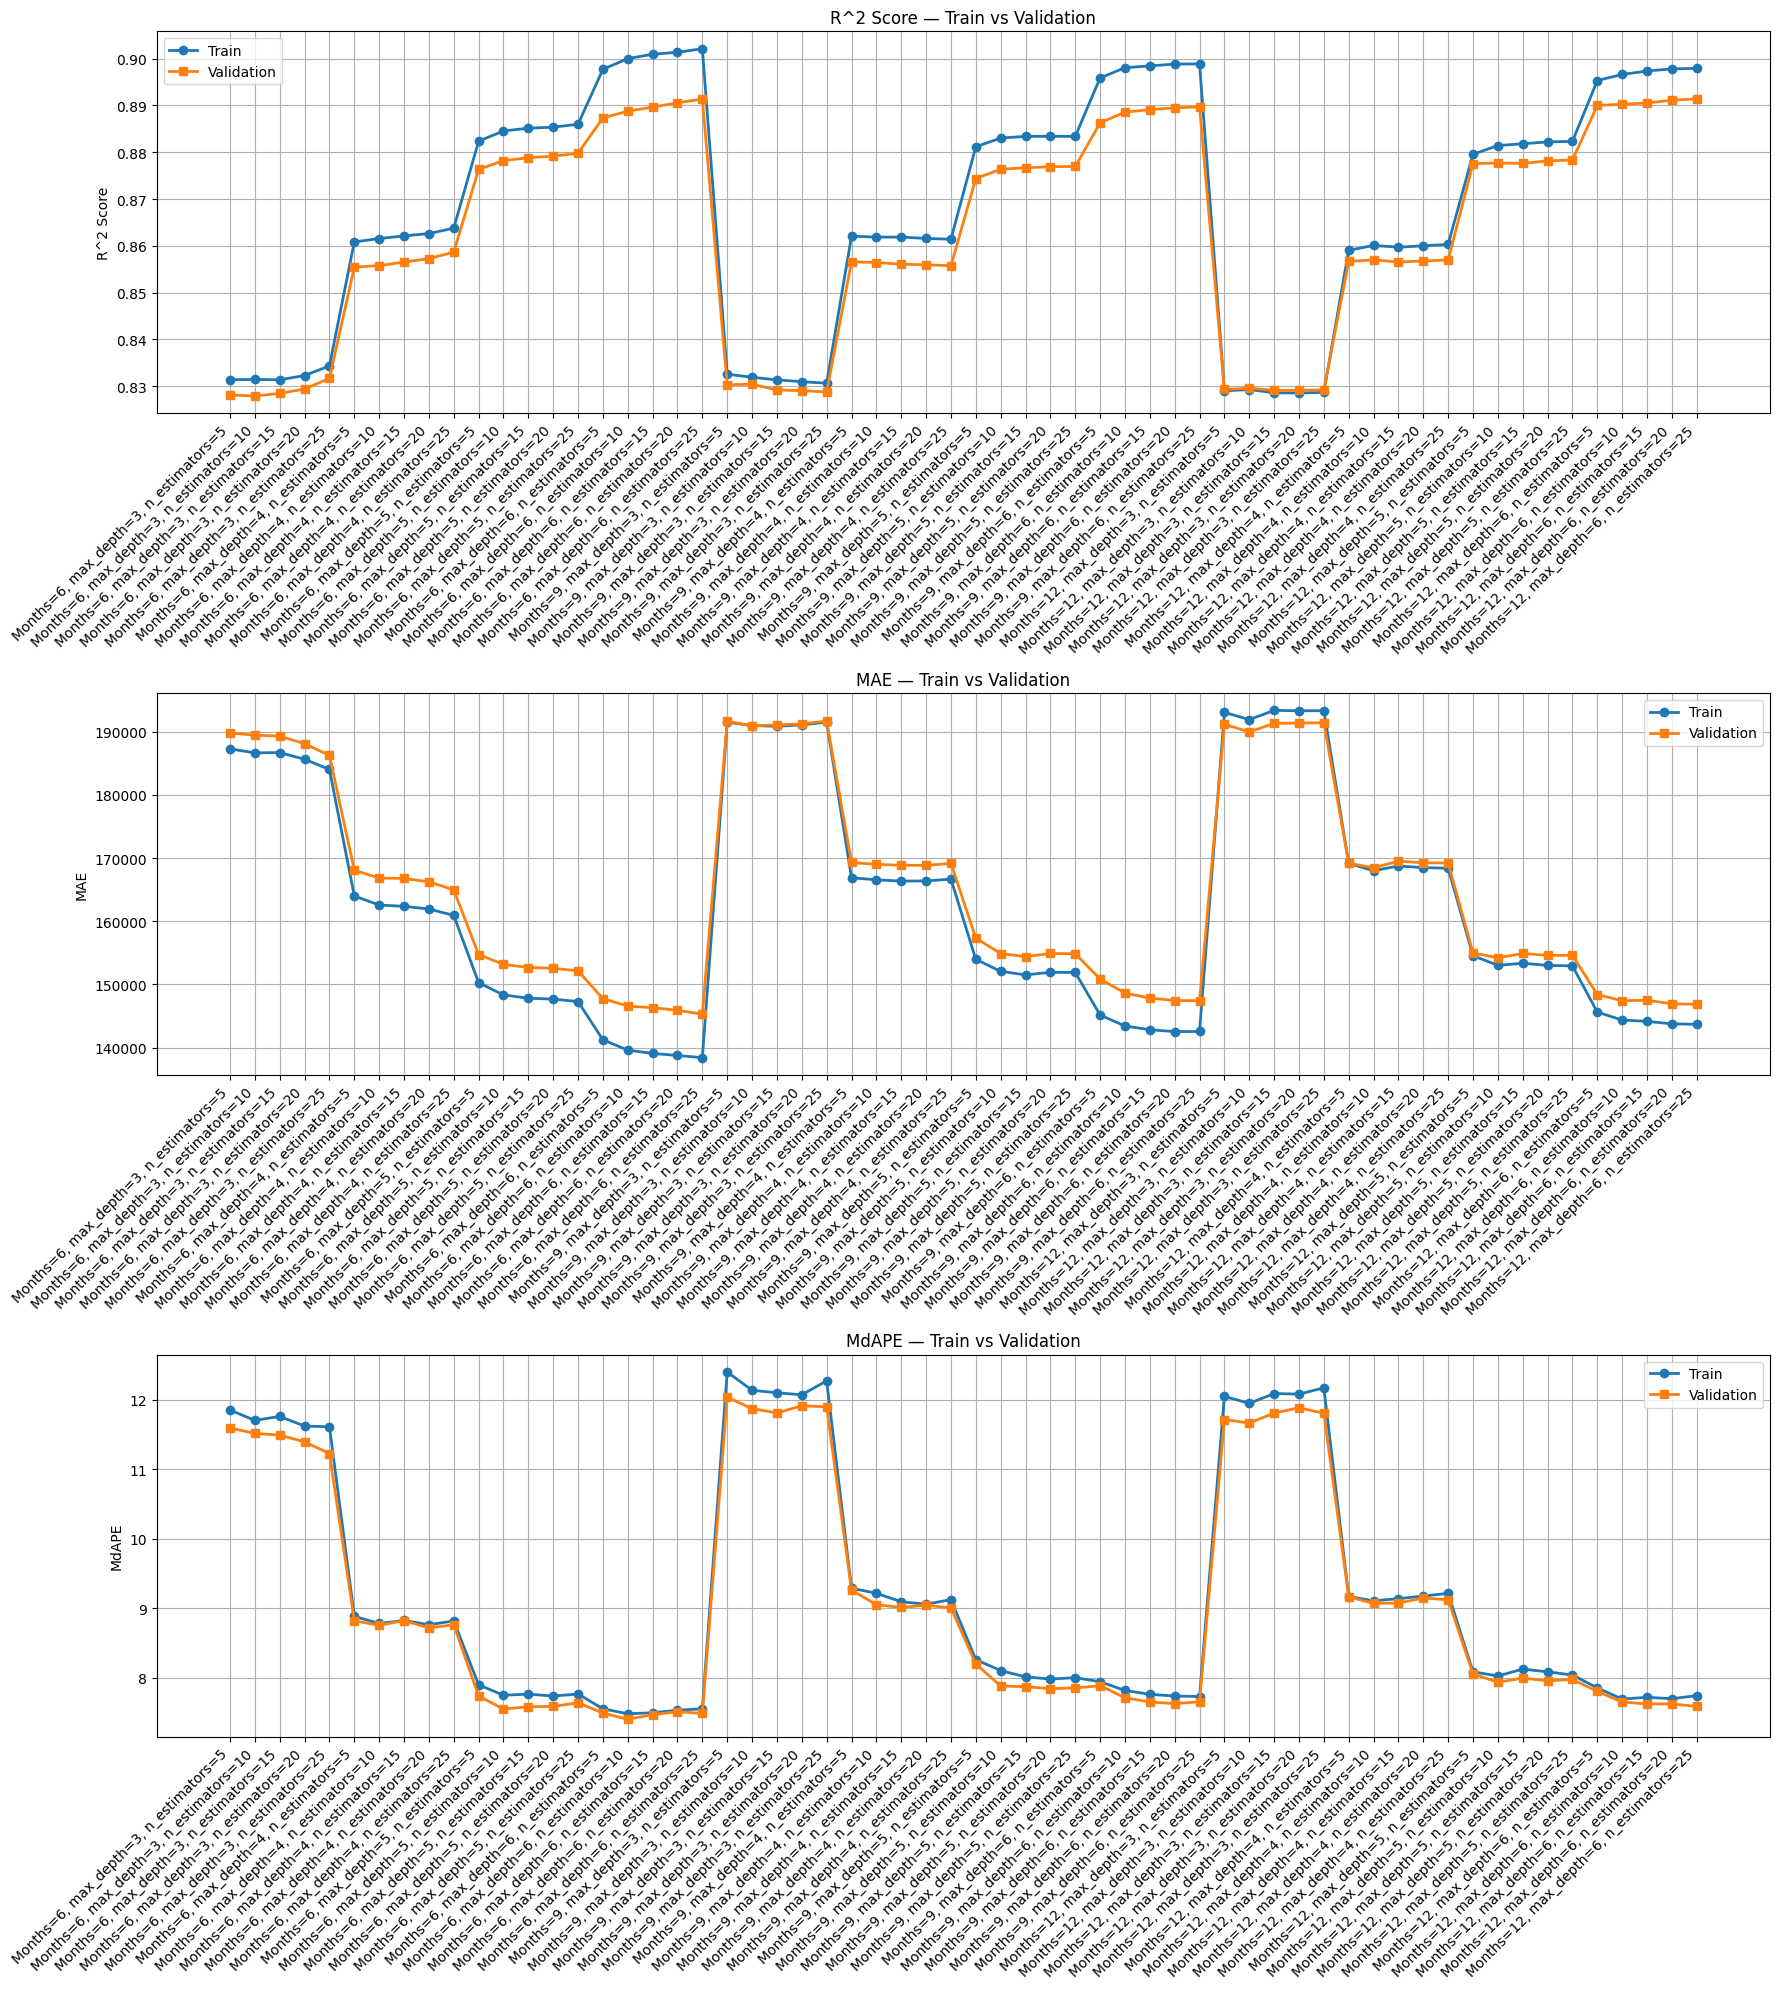

In [28]:
full_feature_set = df_train_full_24mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6, 9, 12, 15, 18, 21, 24]

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [100, 200, 300]
}

results = train_rf_num_months(df_train_full_24mo,
                    df_val_24mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 28 mo subset")

plot_train_vs_val_metrics(results)

We see R-Squared imporoves with depth, but the number of estimators has little effect. For the next run we explore deeper trees, but with fewer estimators. We incldue depth 3 in order to compare against the previous run.

In [29]:
full_feature_set = df_train_full_24mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6, 9, 12, 15, 18, 21, 24]

rf_params = {
    'max_depth': [3, 4, 5, 6],
    'n_estimators': [25, 50, 100]
}

results = train_rf_num_months(df_train_full_24mo,
                    df_val_24mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 28 mo subset")

plot_train_vs_val_metrics(results)

{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 25}, 'Train R^2': 0.8343414441224154, 'Val R^2': 0.8316809559203286, 'Train MAE': 184041.69130098858, 'Val MAE': 186261.90969756895, 'Train MdAPE': np.float64(11.613200293358819), 'Val MdAPE': np.float64(11.227262989044839)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 50}, 'Train R^2': 0.8343100521391068, 'Val R^2': 0.832113670765494, 'Train MAE': 184591.87114781144, 'Val MAE': 186444.60711972715, 'Train MdAPE': np.float64(11.385052984900984), 'Val MdAPE': np.float64(11.123496886941581)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 100}, 'Train R^2': 0.8348700801895456, 'Val R^2': 0.8324924150275563, 'Train MAE': 184563.45132876793, 'Val MAE': 186425.7183427436, 'Train MdAPE': np.float64(11.458194600079704), 'Val MdAPE': np.float64(11.21712848276919)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.863774349040368, 'Val R^2': 0.8586613506288795, 'Train MAE': 16

KeyboardInterrupt: 

{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 5}, 'Train R^2': 0.8313850471662318, 'Val R^2': 0.8281380256001666, 'Train MAE': 187302.1456180947, 'Val MAE': 189809.28395828267, 'Train MdAPE': np.float64(11.85389030985672), 'Val MdAPE': np.float64(11.595189161672508)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 10}, 'Train R^2': 0.831453276912588, 'Val R^2': 0.8279085981336975, 'Train MAE': 186663.29131067073, 'Val MAE': 189457.791891344, 'Train MdAPE': np.float64(11.704751533787565), 'Val MdAPE': np.float64(11.517336641335158)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 15}, 'Train R^2': 0.8313713874351308, 'Val R^2': 0.8284757368634754, 'Train MAE': 186717.08500857334, 'Val MAE': 189325.1874788859, 'Train MdAPE': np.float64(11.762570455000452), 'Val MdAPE': np.float64(11.49201640552406)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 20}, 'Train R^2': 0.8322892266186318, 'Val R^2': 0.8294076575432263, 'Train MAE': 185657.

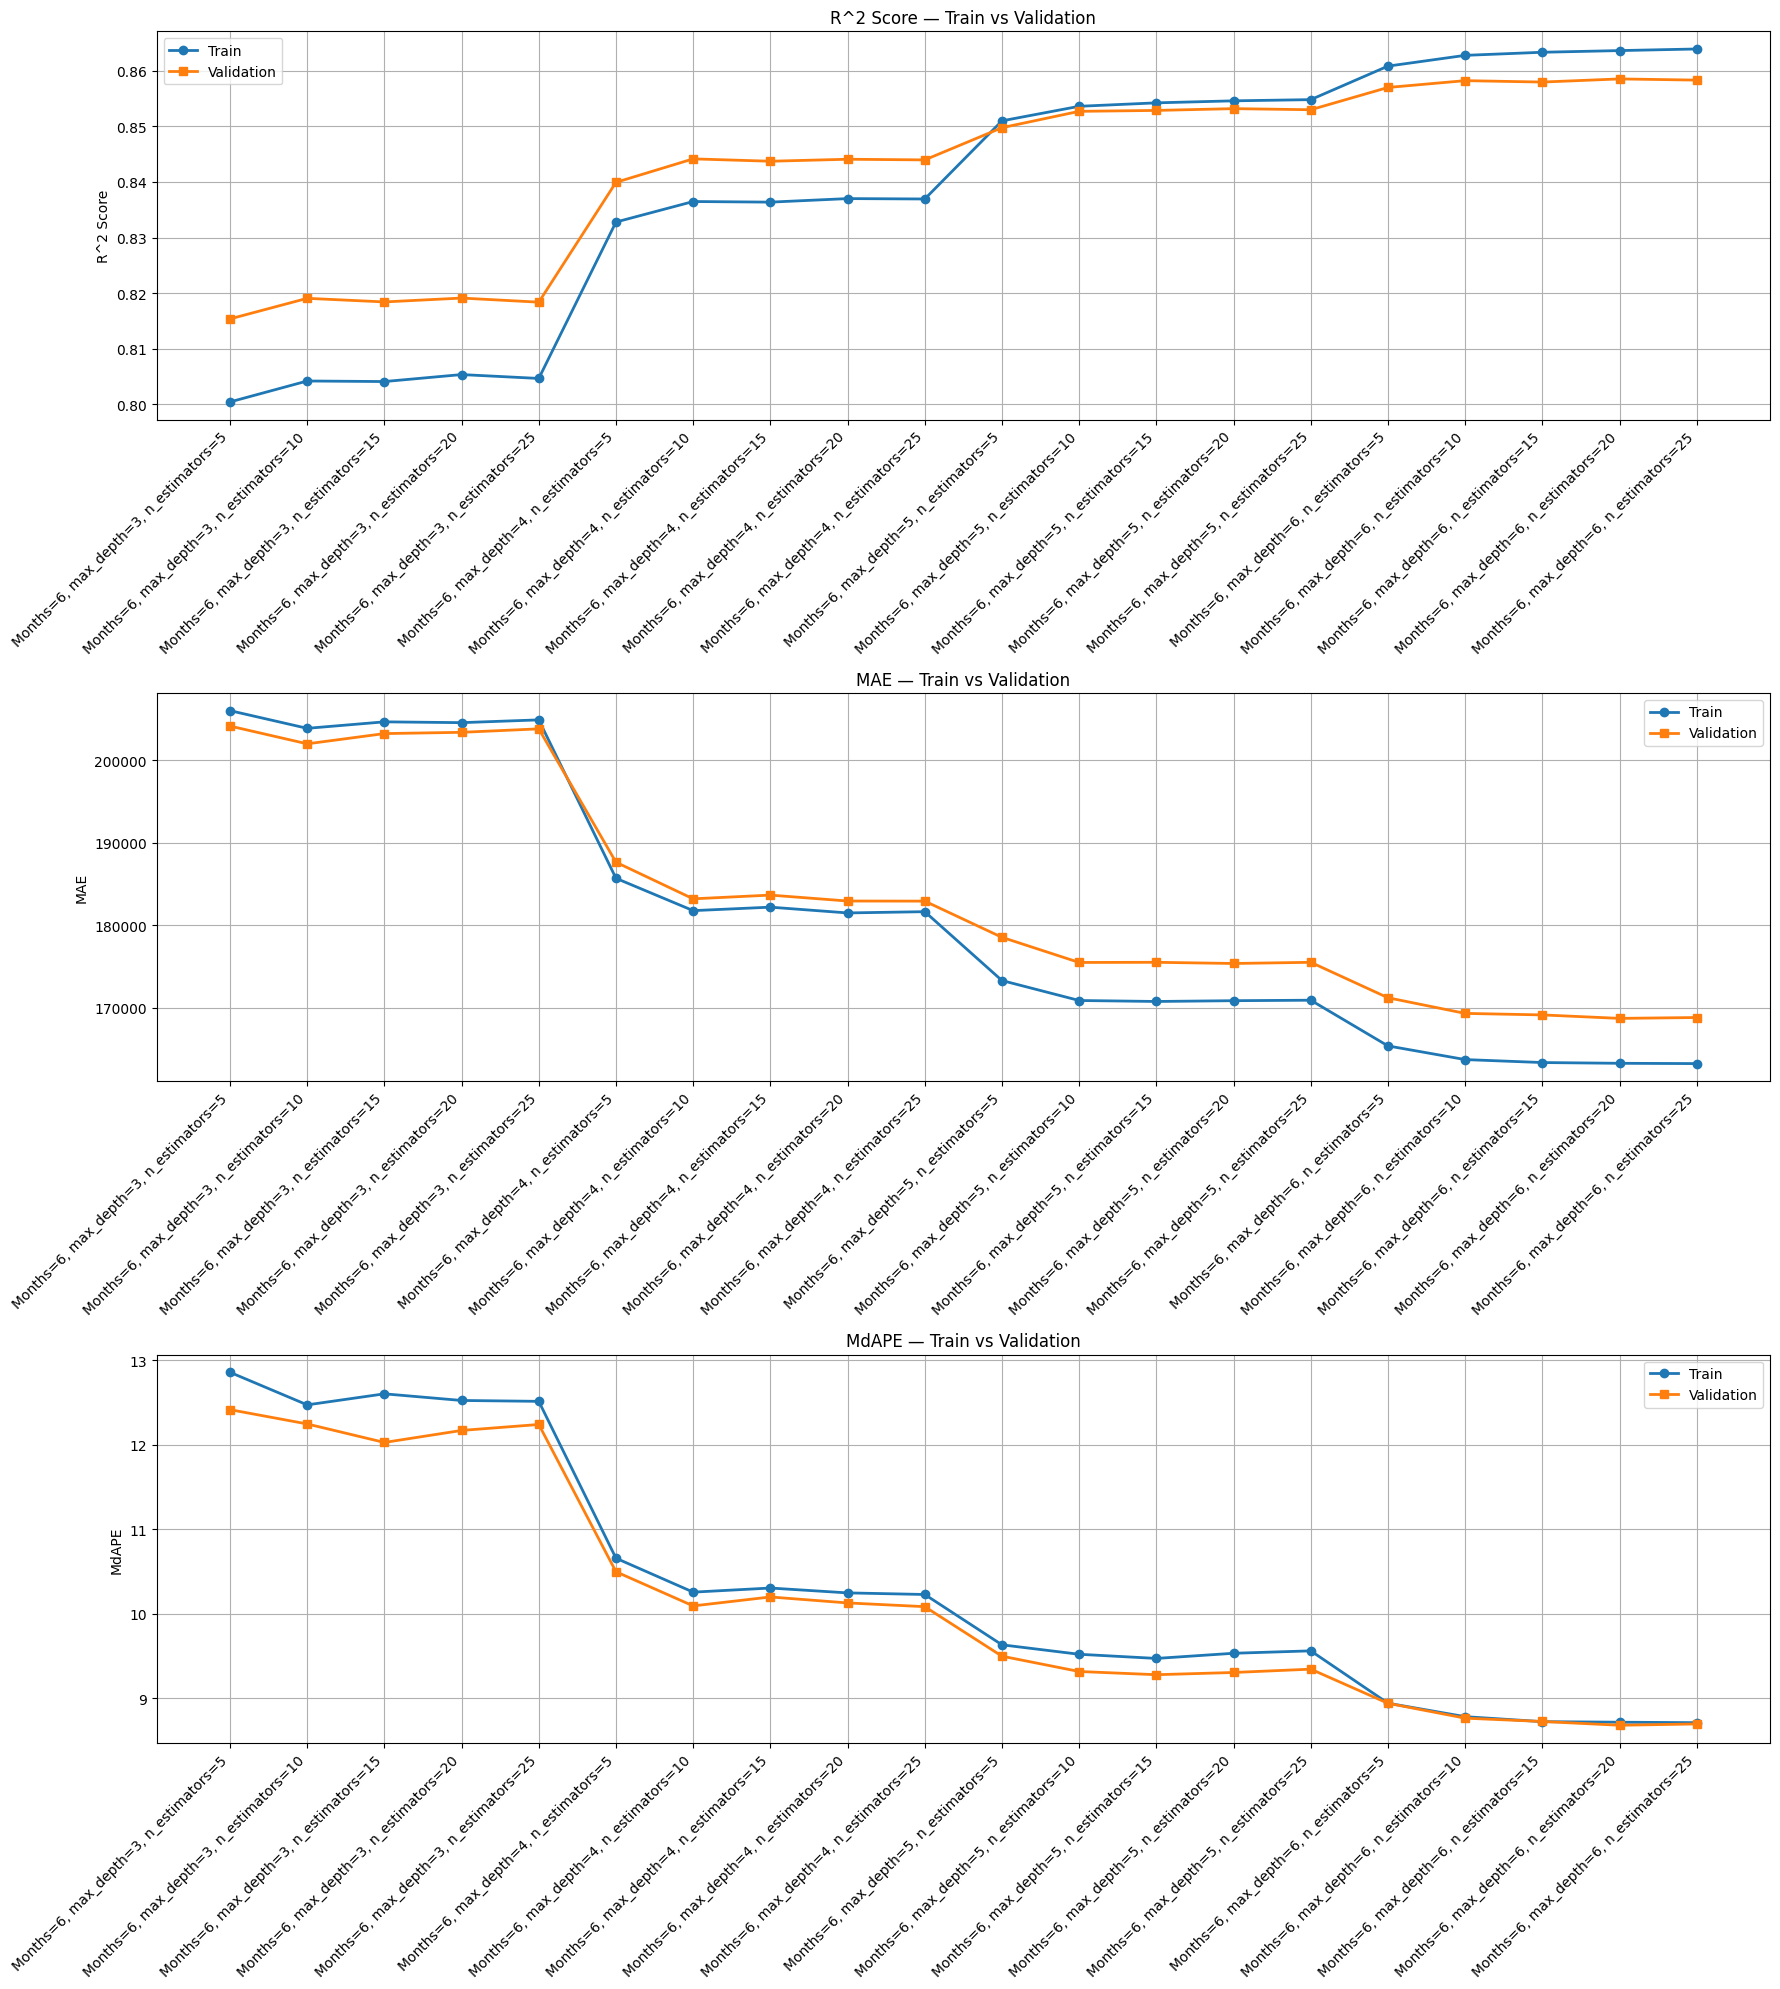

In [21]:
full_feature_set = df_train_full_24mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6, 9, 12]

rf_params = {
    'max_depth': [3, 4, 5, 6],
    'n_estimators': [5, 10, 15, 20, 25]
}

results = train_rf_num_months(df_train_full_24mo,
                    df_val_24mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 28 mo subset")

plot_train_vs_val_metrics(results)

{'num_months': 6, 'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8851299696046161, 'Val R^2': 0.8788249444911624, 'Train MAE': 147820.28167576937, 'Val MAE': 152680.89429131264, 'Train MdAPE': np.float64(7.762105145798329), 'Val MdAPE': np.float64(7.580661262312594)}
{'num_months': 6, 'params': {'max_depth': 5, 'n_estimators': 20}, 'Train R^2': 0.8853570189999732, 'Val R^2': 0.879165220487022, 'Train MAE': 147680.39536622973, 'Val MAE': 152572.14445440497, 'Train MdAPE': np.float64(7.734053604843193), 'Val MdAPE': np.float64(7.584423188325159)}
{'num_months': 6, 'params': {'max_depth': 5, 'n_estimators': 25}, 'Train R^2': 0.8859797481212327, 'Val R^2': 0.8797818728305316, 'Train MAE': 147284.57698050913, 'Val MAE': 152143.06749928452, 'Train MdAPE': np.float64(7.763139597813984), 'Val MdAPE': np.float64(7.63739021728225)}
{'num_months': 6, 'params': {'max_depth': 6, 'n_estimators': 15}, 'Train R^2': 0.9009395586249309, 'Val R^2': 0.8896500700877827, 'Train MAE': 139078.

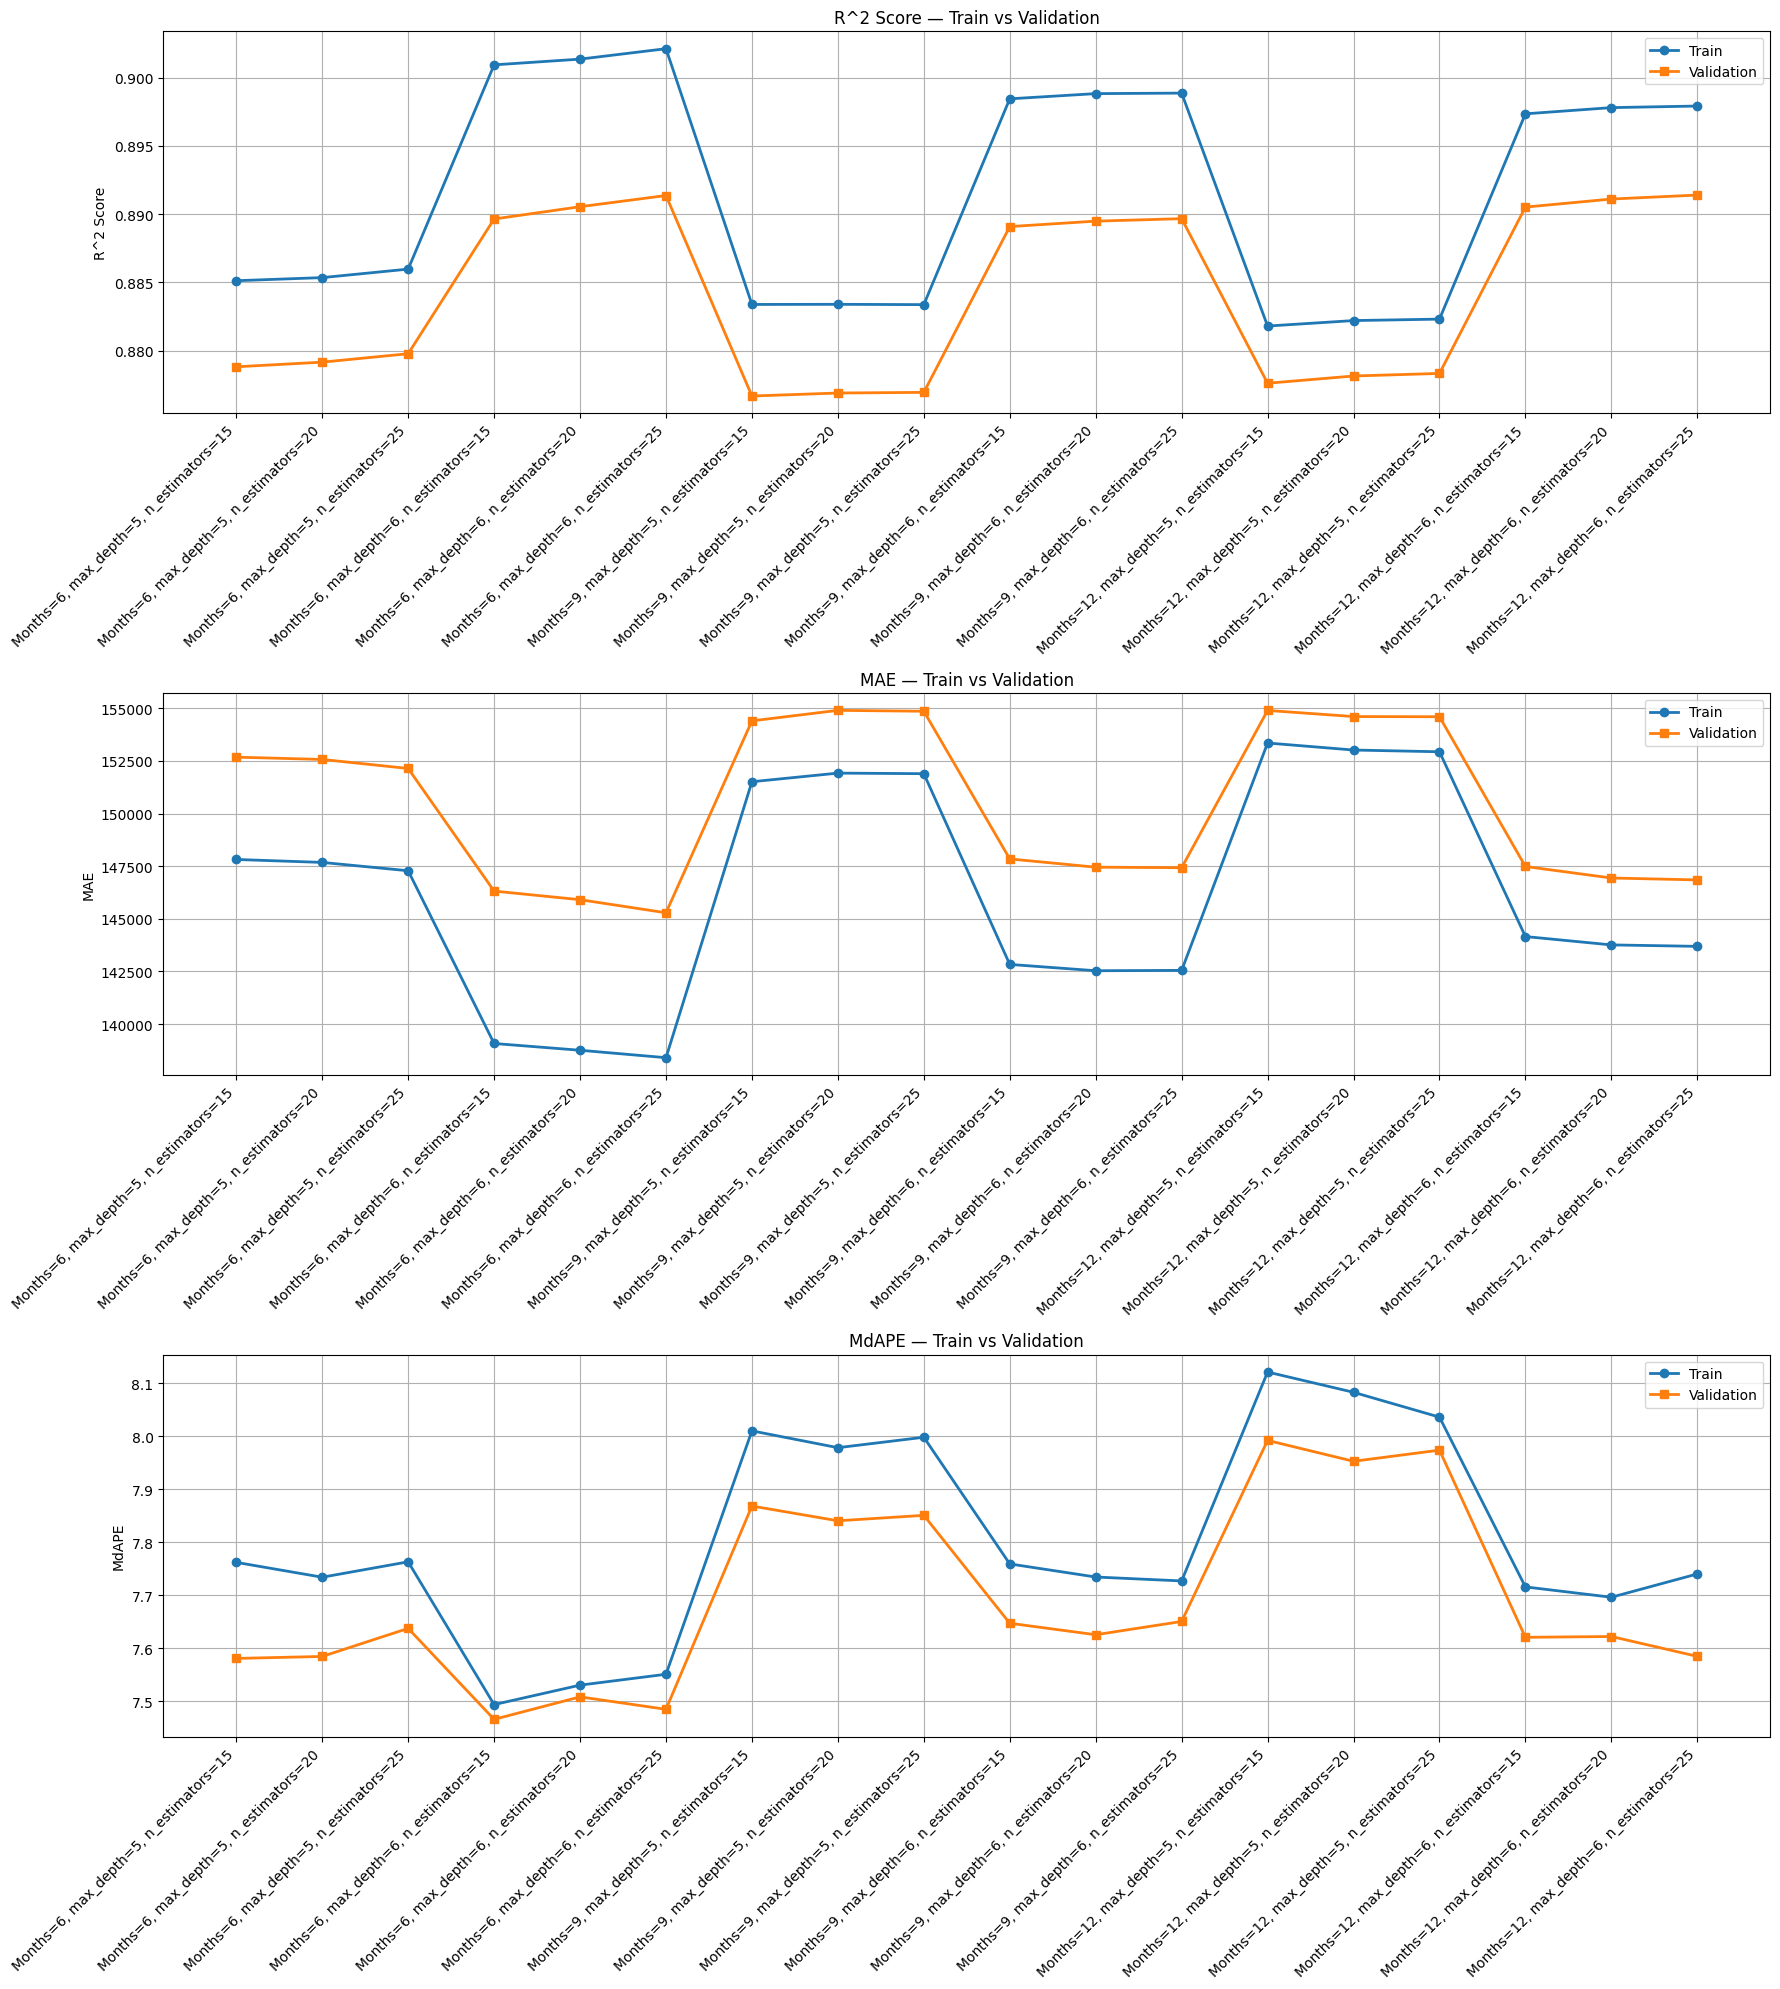

In [22]:
full_feature_set = df_train_full_24mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6, 9, 12]

rf_params = {
    'max_depth': [5, 6],
    'n_estimators': [15, 20, 25]
}

results = train_rf_num_months(df_train_full_24mo,
                    df_val_24mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 28 mo subset")

plot_train_vs_val_metrics(results)

{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 10}, 'Train R^2': 0.831453276912588, 'Val R^2': 0.8279085981336975, 'Train MAE': 186663.29131067073, 'Val MAE': 189457.791891344, 'Train MdAPE': np.float64(11.704751533787565), 'Val MdAPE': np.float64(11.517336641335184)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 20}, 'Train R^2': 0.8322892266186318, 'Val R^2': 0.8294076575432263, 'Train MAE': 185657.57213379574, 'Val MAE': 188113.13844762015, 'Train MdAPE': np.float64(11.622321720026406), 'Val MdAPE': np.float64(11.395513664615851)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 30}, 'Train R^2': 0.8348920295986616, 'Val R^2': 0.8324992913334994, 'Train MAE': 183910.36461931412, 'Val MAE': 185929.24900674427, 'Train MdAPE': np.float64(11.425683084819731), 'Val MdAPE': np.float64(11.017514899330326)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 10}, 'Train R^2': 0.8615543859722049, 'Val R^2': 0.8557802038172787, 'Train MAE': 16

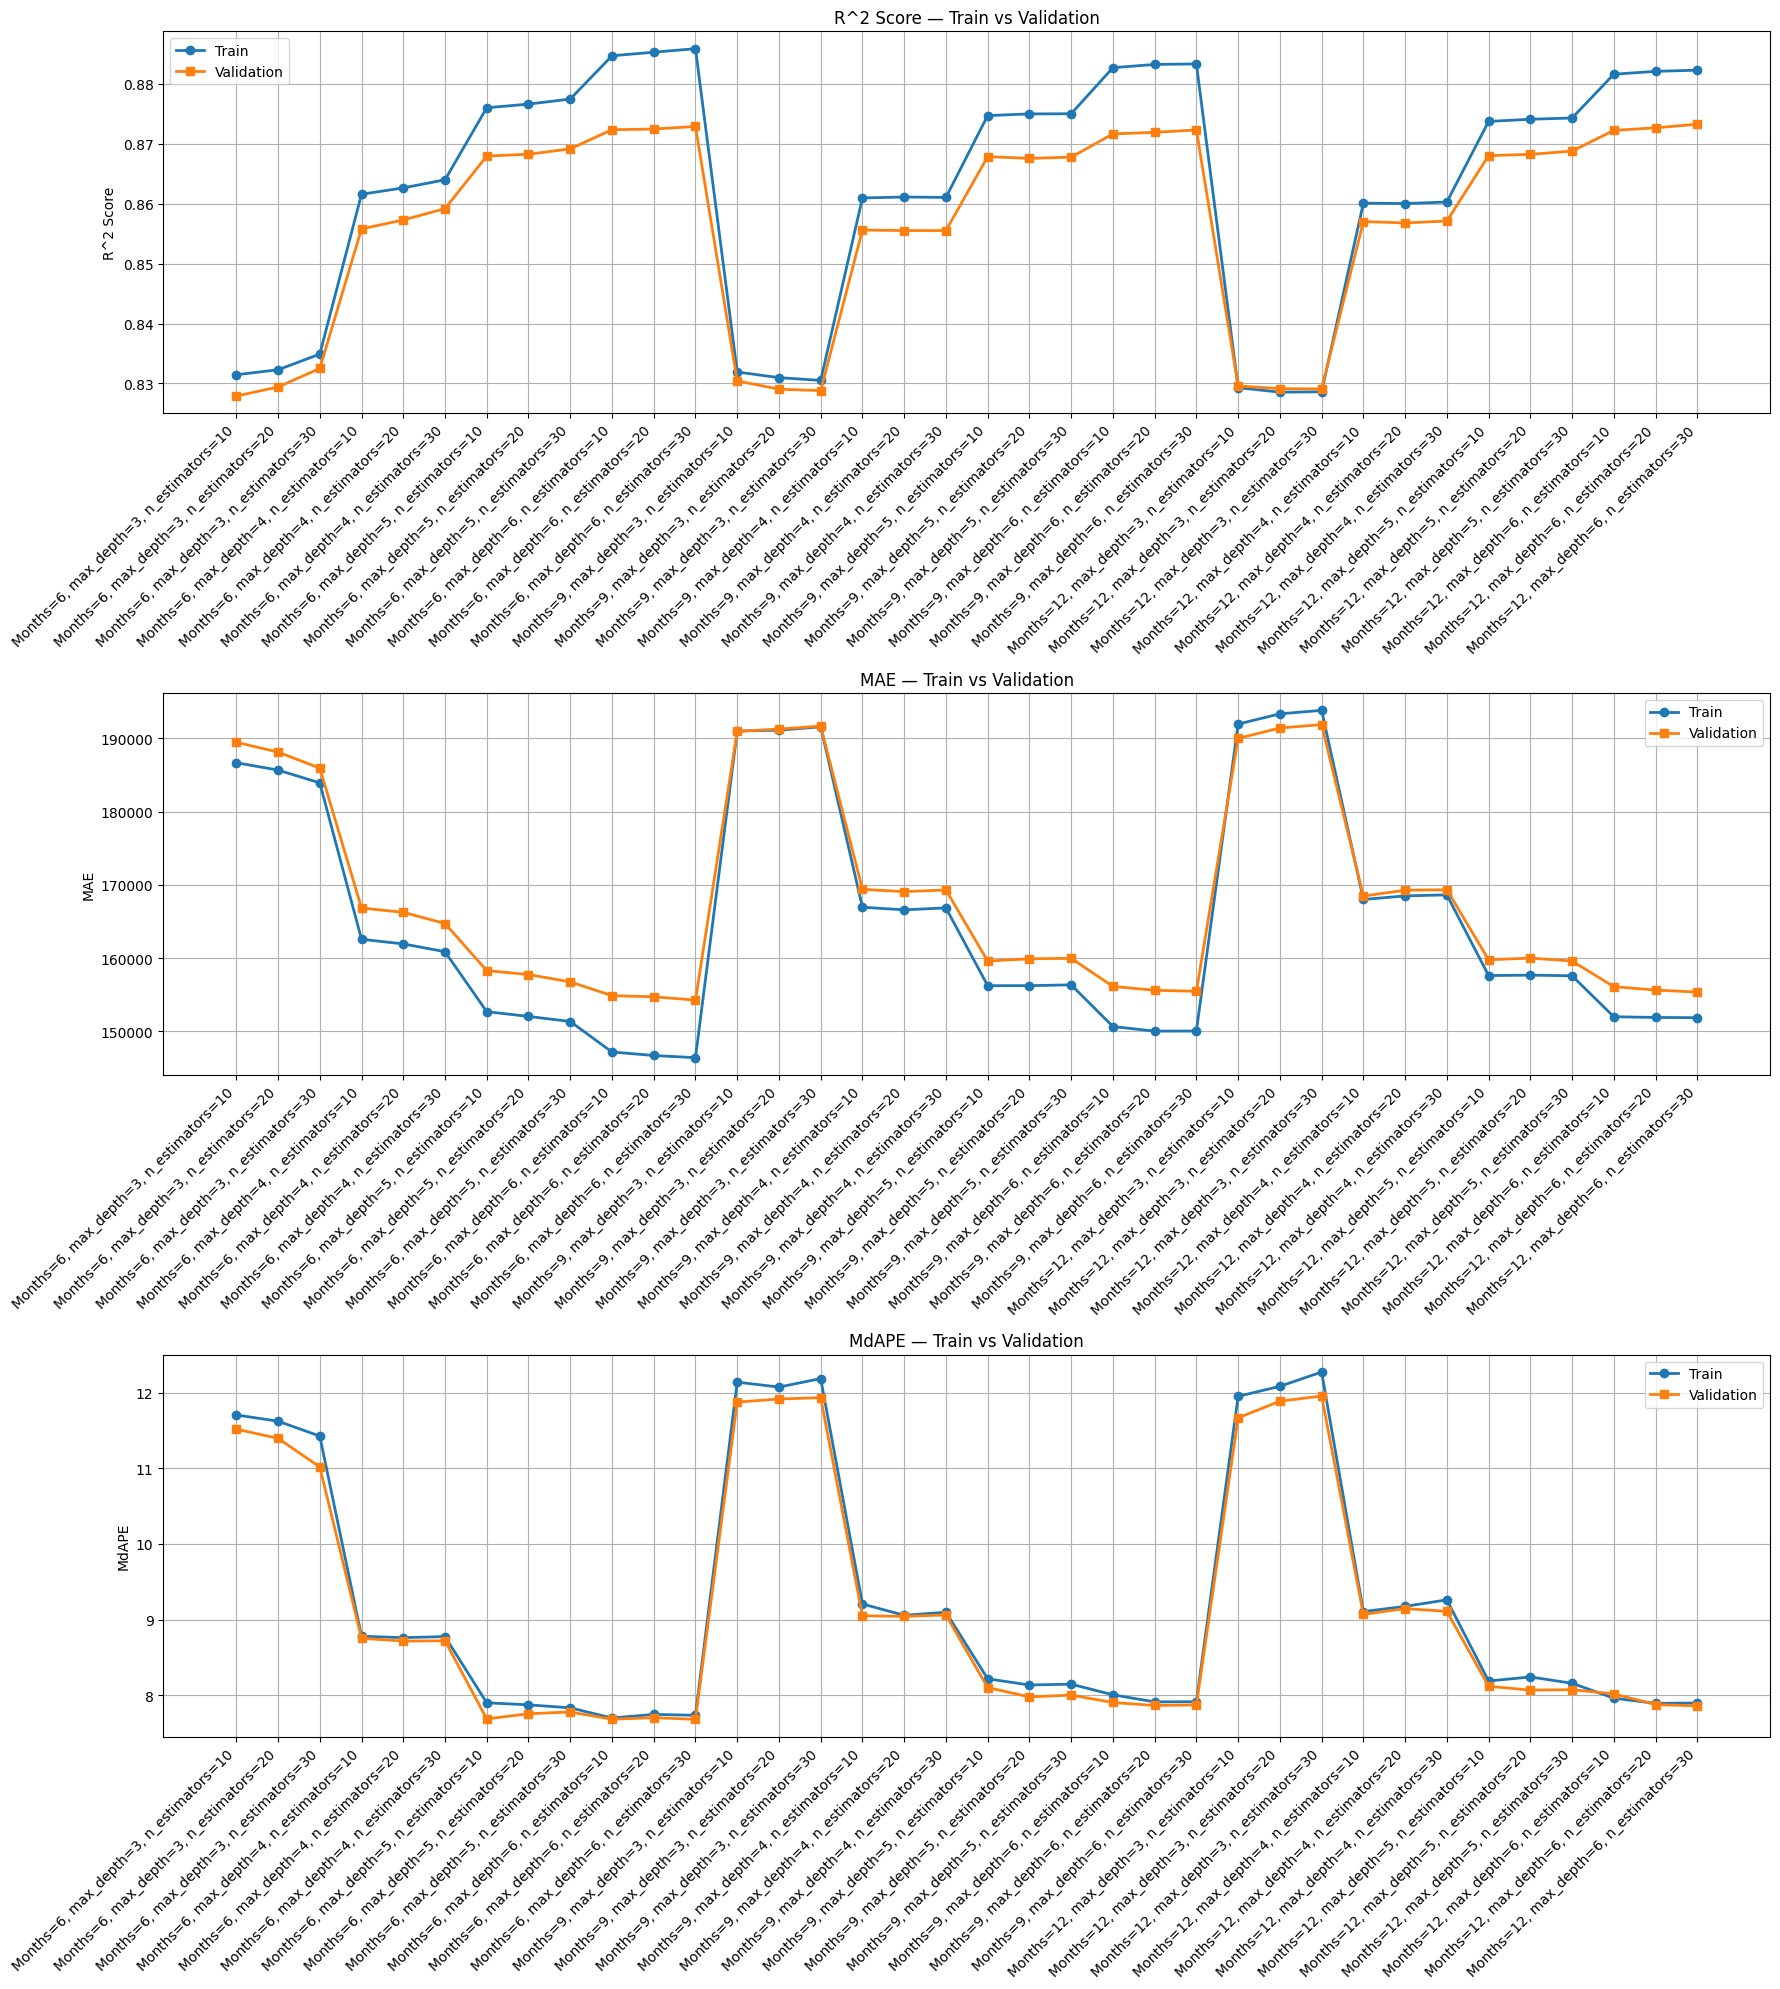

In [23]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

months = [6, 9, 12]

rf_params = {
    'max_depth': [3, 4, 5, 6],
    'n_estimators': [10, 20, 30]
}

results = train_rf_num_months(df_train_full_24mo,
                    df_val_24mo,
                    living_bed_bath_5comps,
                    rf_params, months,
                    "Living Area, # bed/bath + 5 comps, 16 mo subset")

plot_train_vs_val_metrics(results)

## 16 Months of Data

{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 15}, 'Train R^2': 0.8556287293087328, 'Val R^2': 0.8564522754410051, 'Train MAE': 168489.89608452967, 'Val MAE': 171057.25172036394, 'Train MdAPE': np.float64(9.352342194151412), 'Val MdAPE': np.float64(9.056719338017894)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 20}, 'Train R^2': 0.8564499923569459, 'Val R^2': 0.8571352715224854, 'Train MAE': 167749.37360452674, 'Val MAE': 170481.58971108927, 'Train MdAPE': np.float64(9.278845873055404), 'Val MdAPE': np.float64(9.100457317597945)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.8565538818189378, 'Val R^2': 0.8576432074162055, 'Train MAE': 168121.22462195245, 'Val MAE': 170825.95679696836, 'Train MdAPE': np.float64(9.316229809744101), 'Val MdAPE': np.float64(9.089531909905455)}
{'num_months': 6, 'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8788976195633889, 'Val R^2': 0.8766805350289137, 'Train MAE': 15458

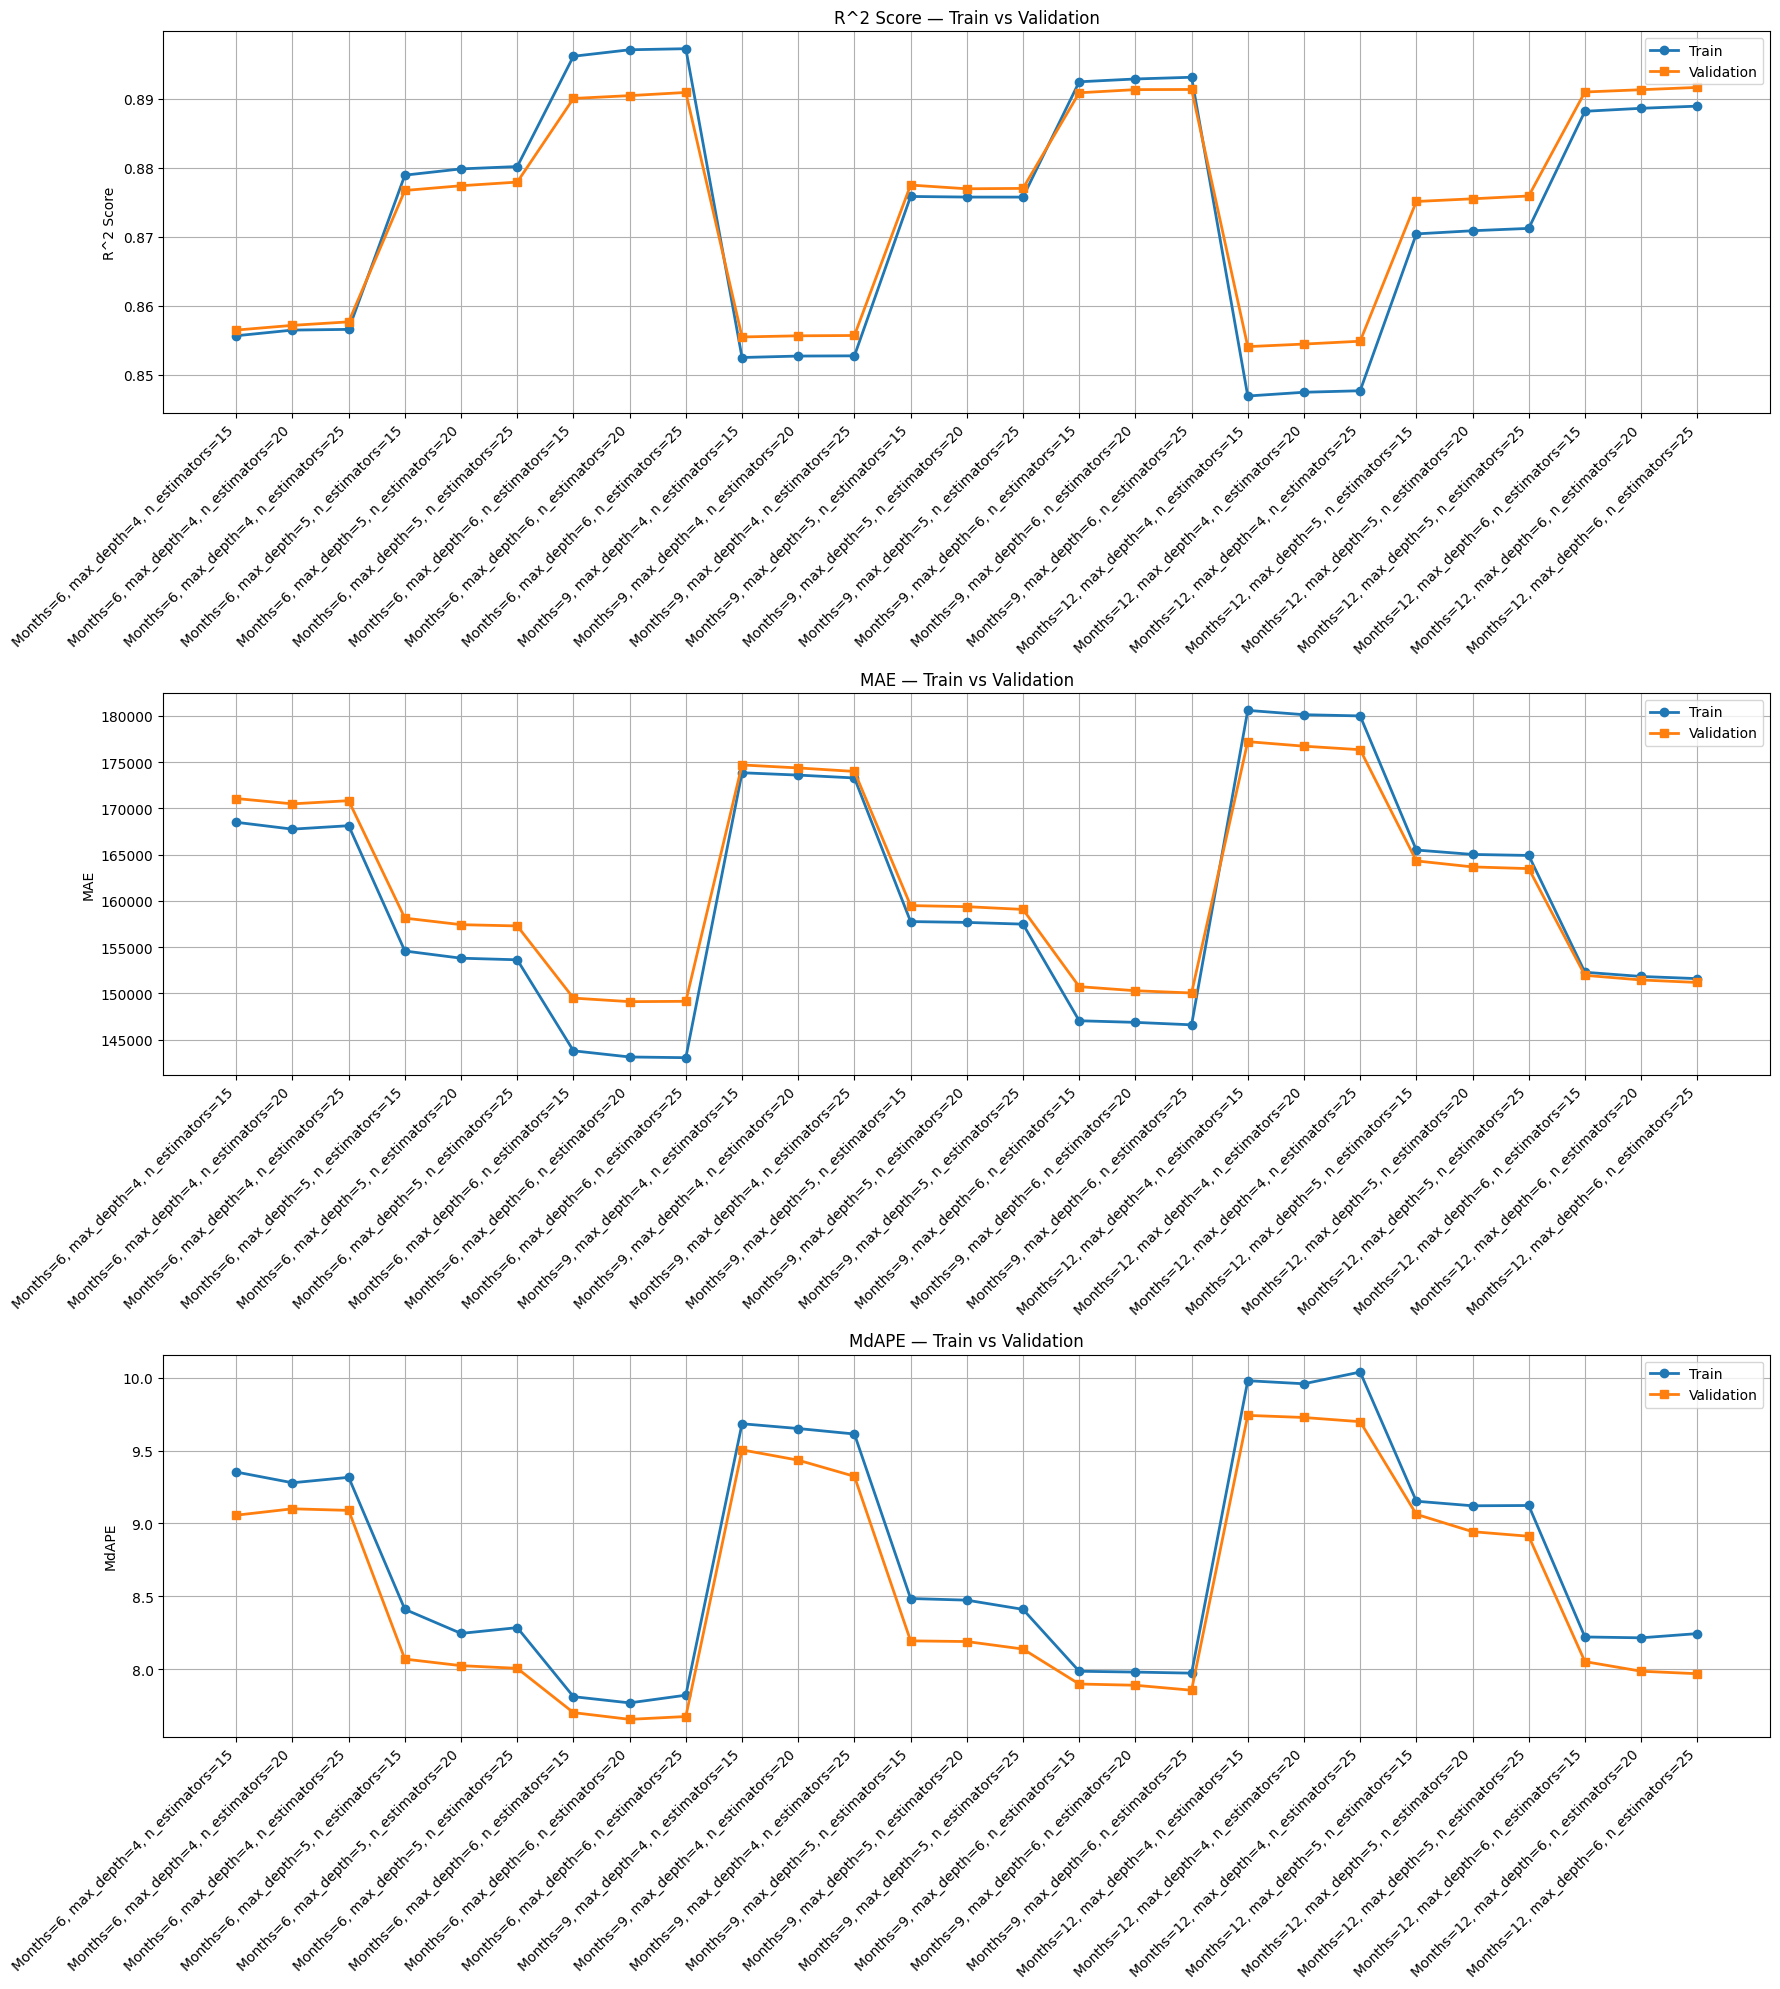

In [24]:
full_feature_set = df_train_full_12mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6, 9, 12]

rf_params = {
    'max_depth': [4, 5, 6],
    'n_estimators': [15, 20, 25]
}

results = train_rf_num_months(df_train_full_12mo,
                    df_val_12mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 16 mo subset")

plot_train_vs_val_metrics(results)

{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 15}, 'Train R^2': 0.851400981772166, 'Val R^2': 0.8533687656191975, 'Train MAE': 169999.6002701012, 'Val MAE': 172229.55866403252, 'Train MdAPE': np.float64(9.389189543971863), 'Val MdAPE': np.float64(9.096296983895535)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 20}, 'Train R^2': 0.8523510226828084, 'Val R^2': 0.8542046381091655, 'Train MAE': 169300.35504654786, 'Val MAE': 171669.31539693536, 'Train MdAPE': np.float64(9.338136847136443), 'Val MdAPE': np.float64(9.12879941113548)}
{'num_months': 6, 'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.8523470584008473, 'Val R^2': 0.8545039445463009, 'Train MAE': 169704.9936471296, 'Val MAE': 172155.36341590938, 'Train MdAPE': np.float64(9.36730632556463), 'Val MdAPE': np.float64(9.156277585778556)}
{'num_months': 6, 'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8672525695637545, 'Val R^2': 0.8647488857041556, 'Train MAE': 159988.212

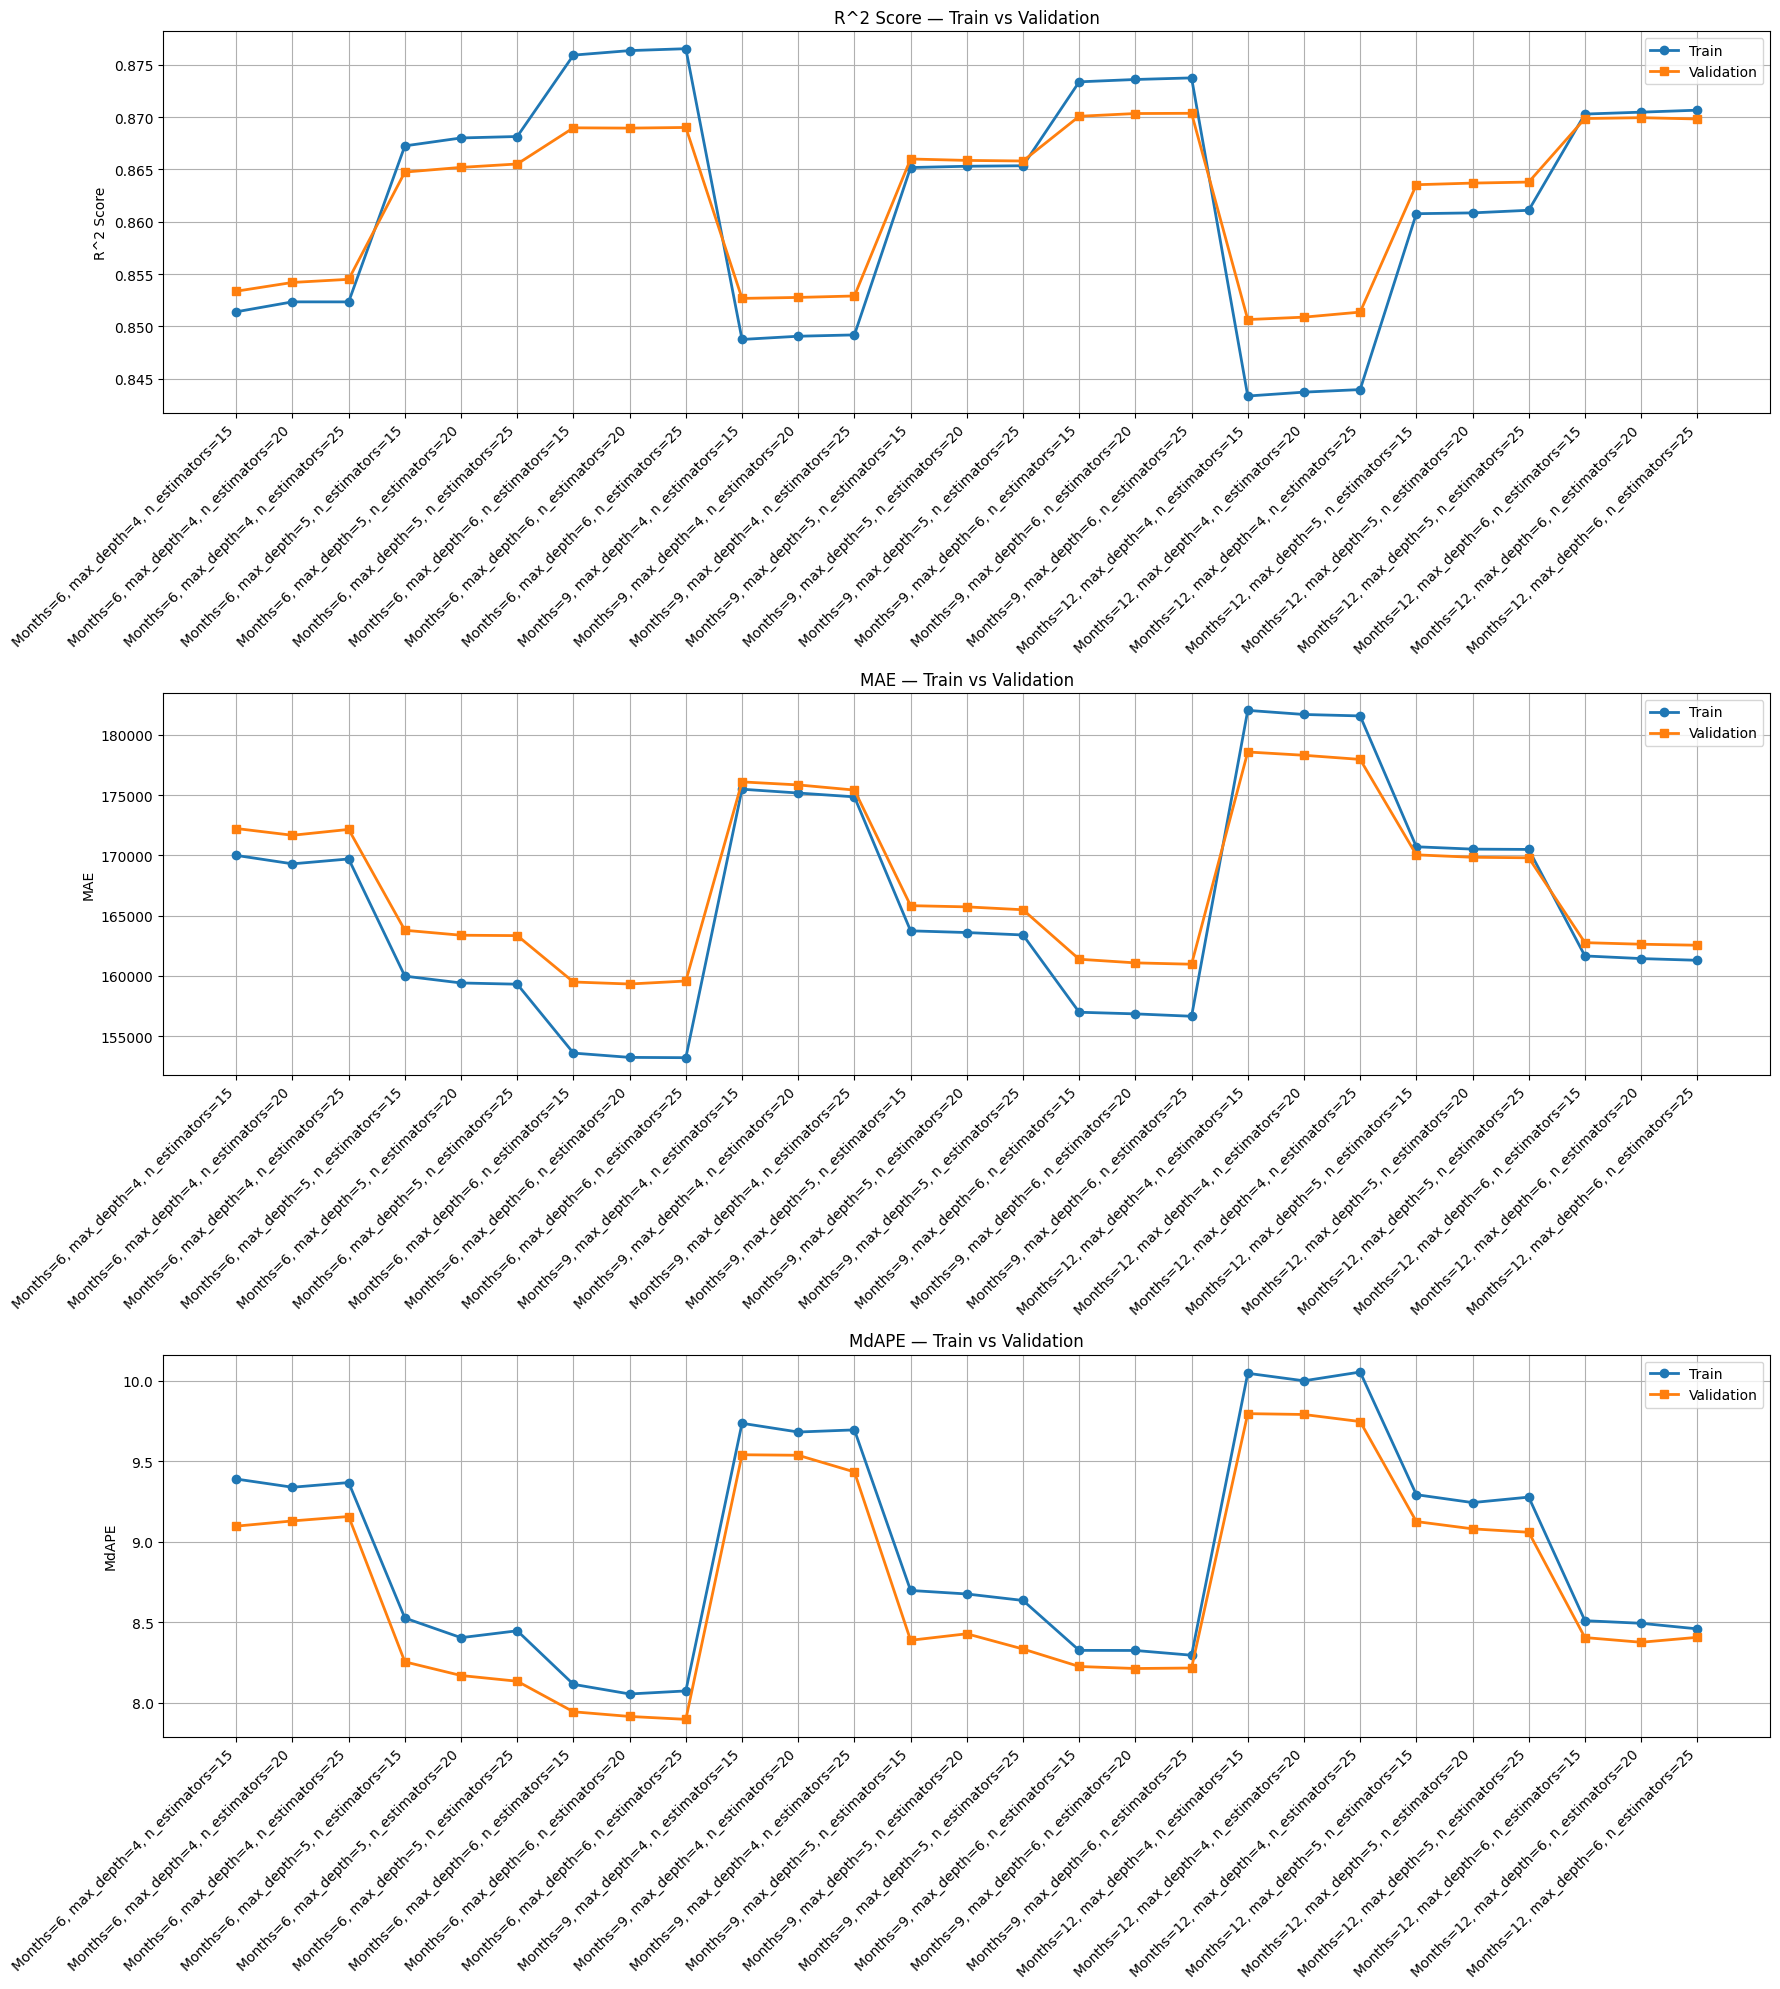

In [25]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

months = [6, 9, 12]

rf_params = {
    'max_depth': [4, 5, 6],
    'n_estimators': [15, 20, 25]
}

results = train_rf_num_months(df_train_full_12mo,
                    df_val_12mo,
                    living_bed_bath_5comps,
                    rf_params,
                    months,
                    "Living Area, # bed/bath + 5 comps, 16 mo subset")

plot_train_vs_val_metrics(results)

## 10 Months of Data

{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 5}, 'Train R^2': 0.8004604349205158, 'Val R^2': 0.8153853544915085, 'Train MAE': 206024.76028913402, 'Val MAE': 204153.18699292152, 'Train MdAPE': np.float64(12.856667629756108), 'Val MdAPE': np.float64(12.414914368546567)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 10}, 'Train R^2': 0.8042230487655294, 'Val R^2': 0.8190849909351119, 'Train MAE': 203879.43287163228, 'Val MAE': 201998.56501795945, 'Train MdAPE': np.float64(12.471641680530904), 'Val MdAPE': np.float64(12.2458612627615)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 15}, 'Train R^2': 0.8041231259736261, 'Val R^2': 0.8184361394174707, 'Train MAE': 204666.07816463136, 'Val MAE': 203241.36699243454, 'Train MdAPE': np.float64(12.602169951620901), 'Val MdAPE': np.float64(12.027021379058388)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 20}, 'Train R^2': 0.8053771575094255, 'Val R^2': 0.8191323456110594, 'Train MAE': 20

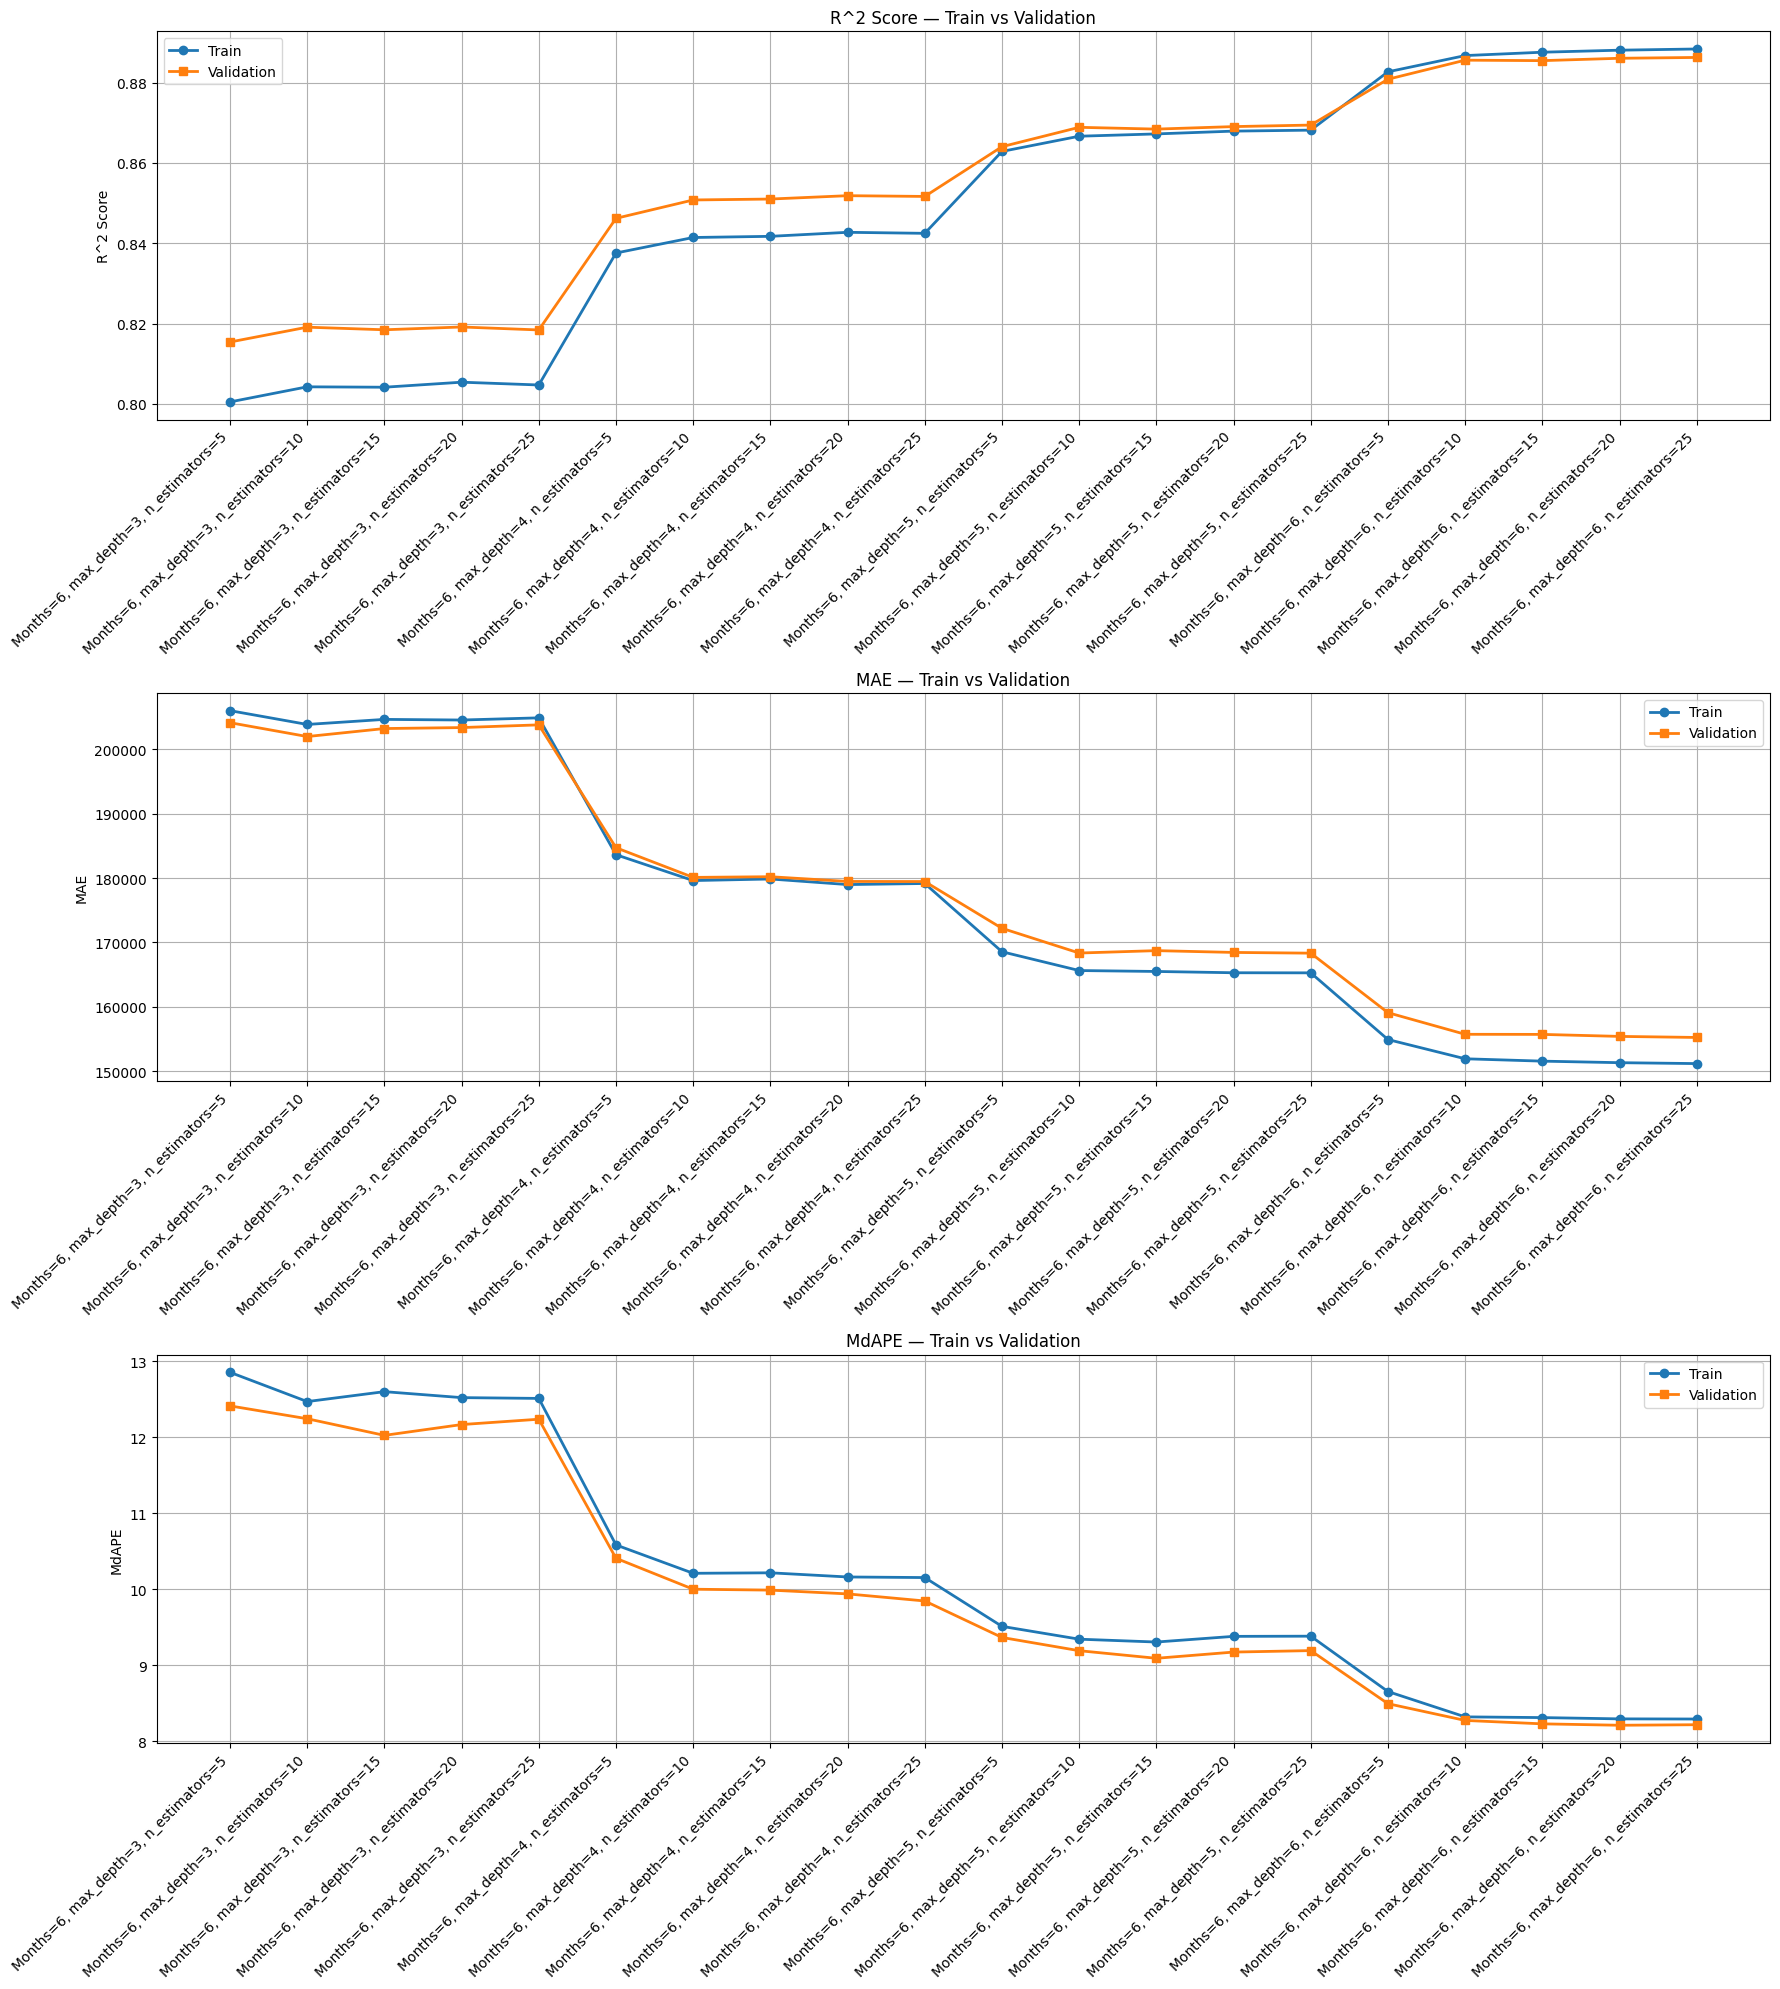

In [26]:
full_feature_set = df_train_full_6mo.drop(columns=["ClosePrice"]).columns.tolist()

months = [6]

rf_params = {
    'max_depth': [3, 4, 5, 6],
    'n_estimators': [5, 10, 15, 20, 25]
}

results = train_rf_num_months(df_train_full_6mo,
                    df_val_6mo,
                    full_feature_set,
                    rf_params,
                    months,
                    "Full Feature Set, 10 mo subset")

plot_train_vs_val_metrics(results)

{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 5}, 'Train R^2': 0.8004604349205158, 'Val R^2': 0.8153853544915084, 'Train MAE': 206024.76028913402, 'Val MAE': 204153.18699292152, 'Train MdAPE': np.float64(12.856667629756108), 'Val MdAPE': np.float64(12.414914368546567)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 10}, 'Train R^2': 0.8042230487655294, 'Val R^2': 0.8190849909351119, 'Train MAE': 203879.43287163228, 'Val MAE': 201998.56501795945, 'Train MdAPE': np.float64(12.471641680530904), 'Val MdAPE': np.float64(12.2458612627615)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 15}, 'Train R^2': 0.8041231259736261, 'Val R^2': 0.8184361394174707, 'Train MAE': 204666.07816463136, 'Val MAE': 203241.36699243454, 'Train MdAPE': np.float64(12.602169951620901), 'Val MdAPE': np.float64(12.027021379058388)}
{'num_months': 6, 'params': {'max_depth': 3, 'n_estimators': 20}, 'Train R^2': 0.8053771575094255, 'Val R^2': 0.8191323456110594, 'Train MAE': 20

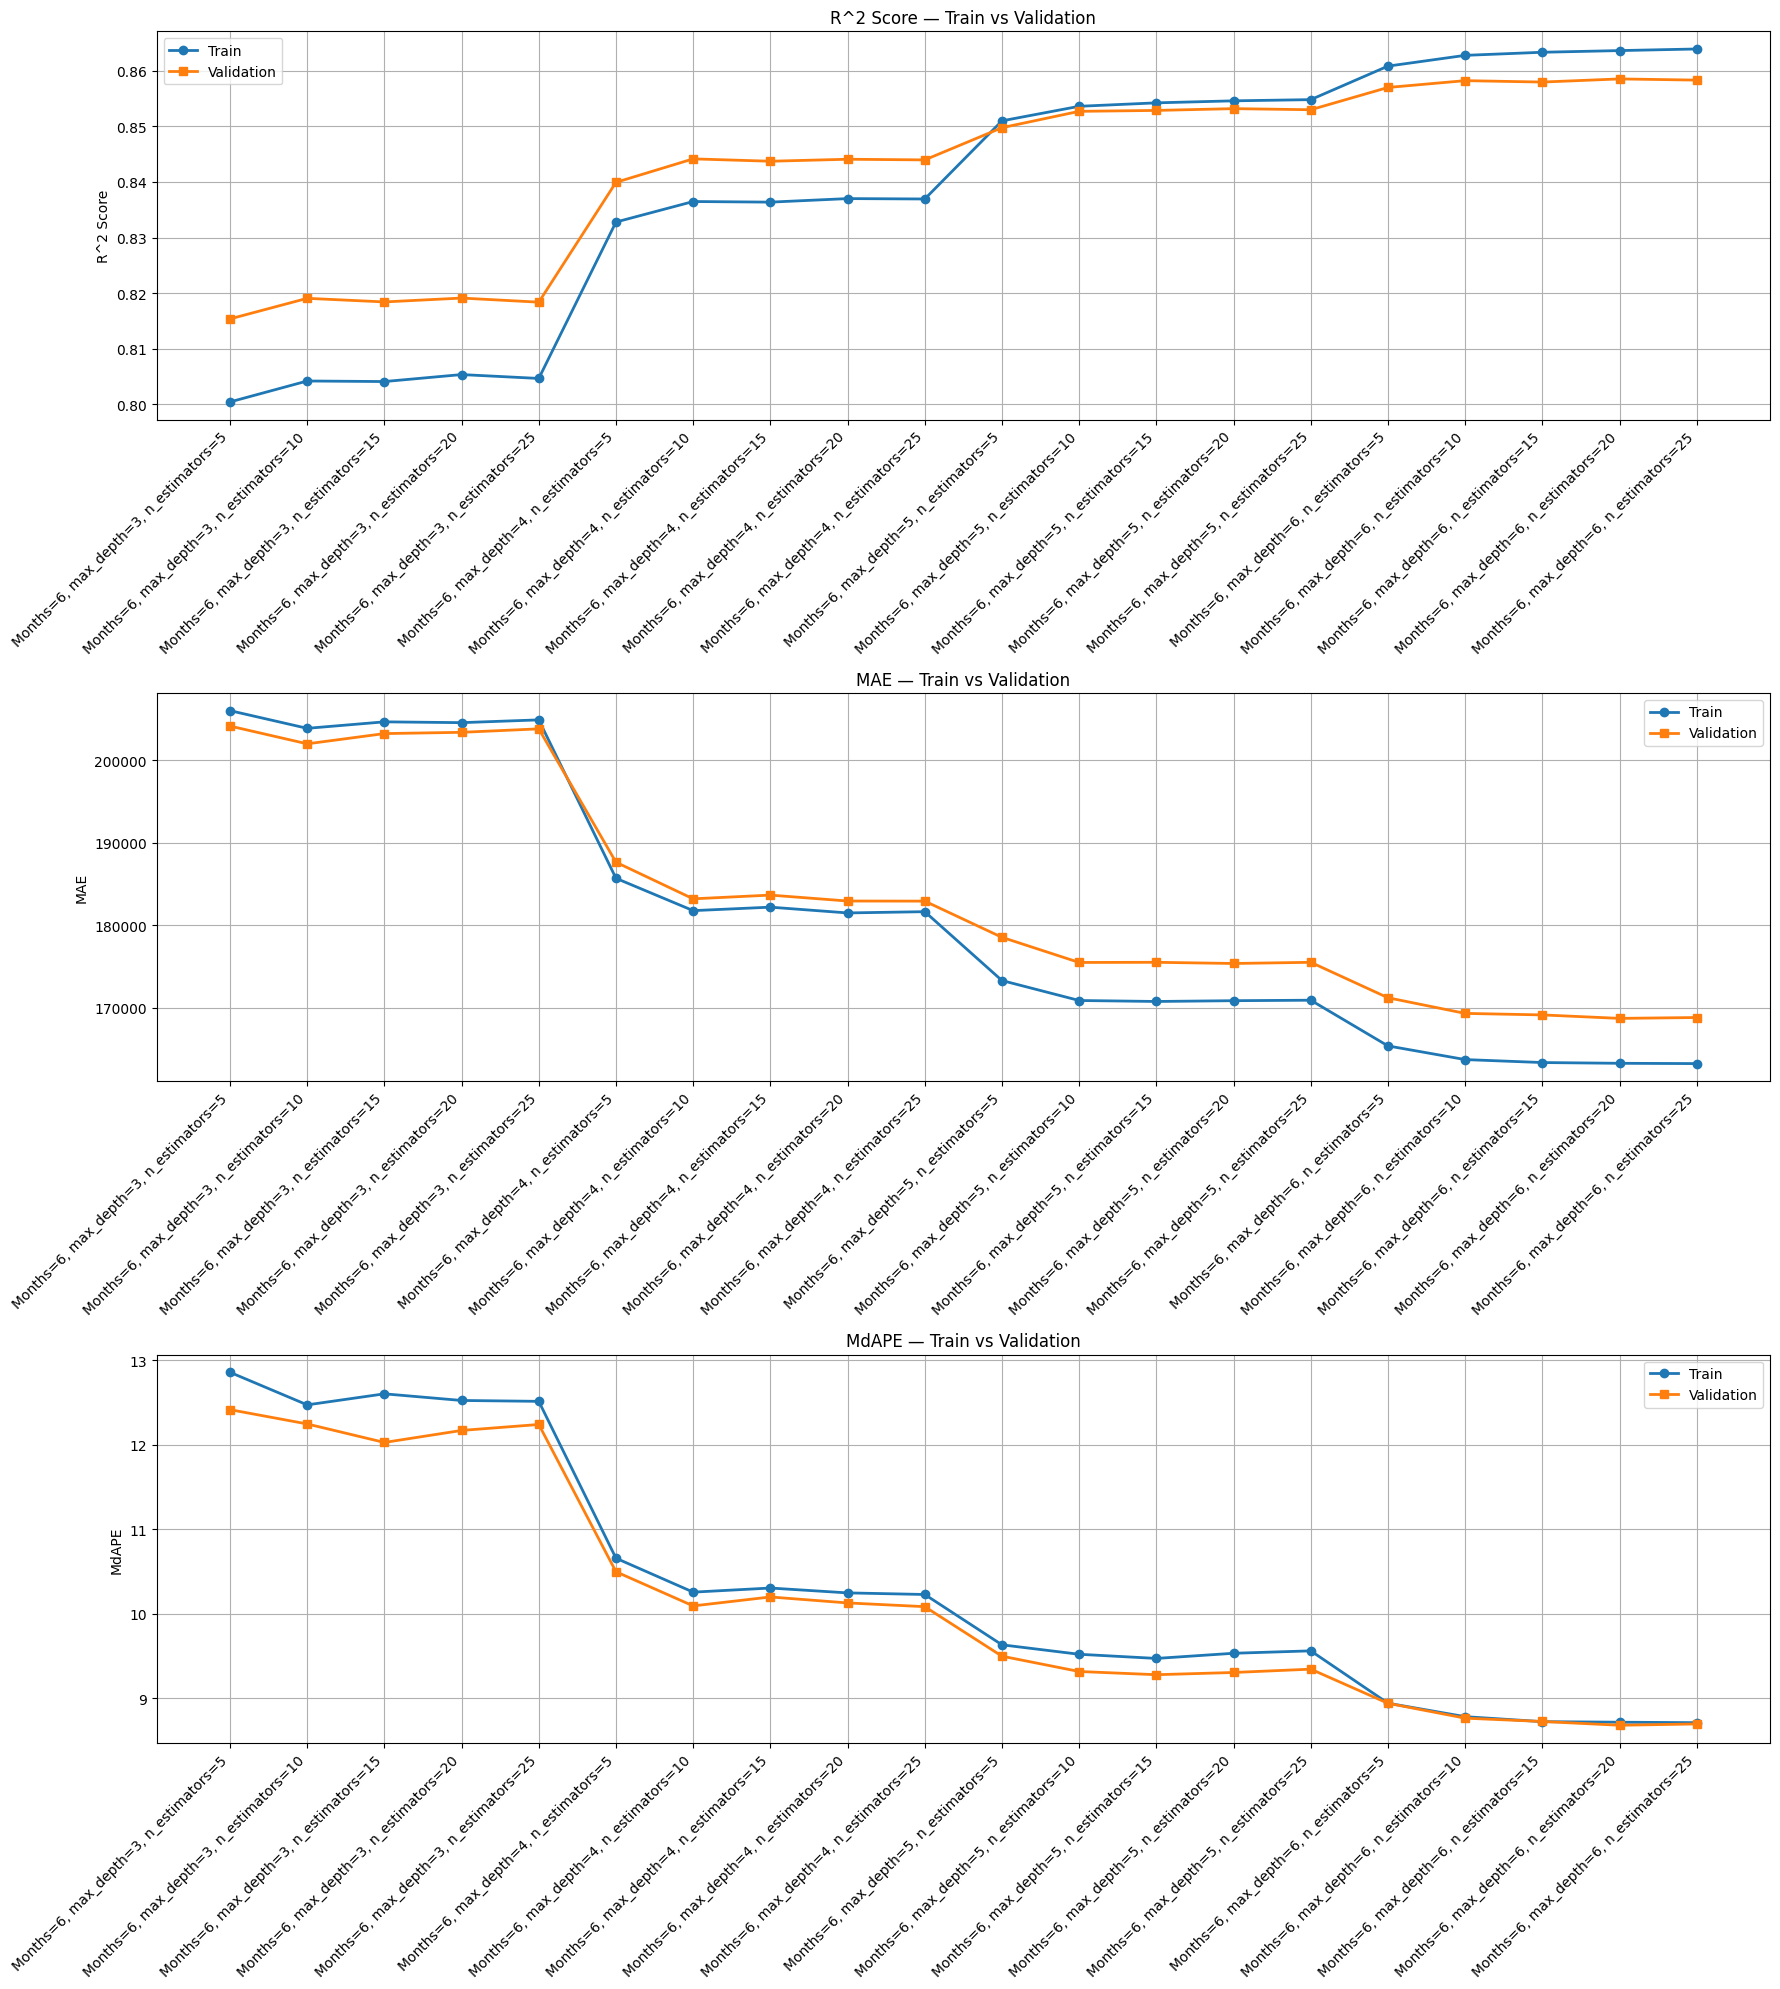

In [27]:
from numpy._core.multiarray import result_type
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

months = [6]

rf_params = {
    'max_depth': [3, 4, 5, 6],
    'n_estimators': [5, 10, 15, 20, 25]
}

results = train_rf_num_months(df_train_full_6mo,
                    df_val_6mo,
                    living_bed_bath_5comps,
                    rf_params,
                    months,
                    "Living Area, # bed/bath + 5 comps, 10 mo subset")

plot_train_vs_val_metrics(results)